```markdown
# Honours Research Project: Spatial Fire Risk Index (FRI) & Helicopter Landing Zone (HLZ) Suitability in Niue

**Brianna Robertson**

---

## 📖 Theoretical & Methodological Framework

This project implements and adapts a remote sensing-based **Multi-Criteria Evaluation (MCE)** framework to assess spatial wildfire susceptibility on the island of Niue. The core methodology is grounded in established remote-sensing literature and specifically adapted for operational humanitarian assistance and disaster relief (HA/DR) scenarios.

### 1. Fuel as the Critical Factor: Chuvieco & Congalton (1989)
Following the seminal methodology established by **Chuvieco and Congalton (1989)** (*"Applying GIS to Wildfire Danger Mapping"*), **Land Cover** is treated as the primary factor influencing wildfire initiation and propagation. In their pioneering study, they demonstrated that fuel types (derived from satellite land-cover classification) represent the highest susceptibility weight due to their direct relationship with combustible biomass and fire behavior.

Accordingly, our **Weighted Fire Risk Index (FRI)** allocates the highest relative influence to our fuel proxy:
$$\text{FRI} = (0.50 \times \text{Fuel Score}) + (0.35 \times \text{Moisture Score}) + (0.15 \times \text{Slope Score})$$

* **Fuel (50% weight):** Modeled using Sentinel-2 Normalised Difference Vegetation Index (NDVI) as an empirical proxy for live green biomass and canopy density, categorized into Built-up/Bare Soil, Agricultural Scrub, and Dense Native Forest.
* **Moisture (35% weight):** Modeled using Sentinel-2 Normalised Difference Water Index (NDWI) to capture vegetation canopy water stress.
* **Topography (15% weight):** Modeled using SRTM Digital Elevation Model (DEM) Slope, reflecting how steeper terrain accelerates fire propagation through convective preheating.

### 2. Niue-Specific Operational Adaptations
To translate this academic framework into an actionable HA/DR decision-support tool, two specific operational constraints were introduced:
* **The Coastal Reef Elevation Mask ($>10\text{m}$):** Niue is a raised coral atoll surrounded by a sea-level fringing reef flat. To prevent ocean-reef interfaces from skewing terrestrial statistics, we applied a strict digital elevation mask limiting all spatial calculations to the terrestrial plateau above **10 meters elevation**.
* **Helicopter Landing Zone (HLZ) Suitability:** To support emergency air logistics, we identified candidate landing zones on the terrestrial plateau where the terrain is highly accessible (**Slope $< 5^\circ$**), clear of heavy fuel obstructions (**Fuel Score $\le 2$**, excluding dense forests), and located strictly on the secure inland shelf.
```

In [24]:
import ee
import geemap
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import pandas as pd

# Authenticate and initialize Earth Engine once for the entire session
ee.Authenticate()
ee.Initialize(project='brob-503906')

In [25]:
# MAP OF SITES
from ipyleaflet import ScaleControl, WidgetControl
import ipywidgets as widgets

# Function to generate exact uniform 3km x 3km squares
def create_uniform_square(center_lon, center_lat, size_km=3.0):
    delta_deg = (size_km / 111.0) / 2.0
    return ee.Geometry.BBox(
        center_lon - delta_deg,
        center_lat - delta_deg,
        center_lon + delta_deg,
        center_lat + delta_deg
    )

# Onshore Coordinates
alofi_bbox = create_uniform_square(-169.910, -19.060, size_km=3.0)   # Alofi
vaiea_bbox = create_uniform_square(-169.890, -19.120, size_km=3.0)   # Vaiea
huvalu_bbox = create_uniform_square(-169.825, -19.085, size_km=3.0)  # Huvalu

# Initialize Map
Map = geemap.Map(center=[-19.05, -169.86], zoom=11.4, zoom_snap=0.1, zoom_delta=0.2)
Map.add_basemap('SATELLITE')


# Add Bounding Boxes
Map.addLayer(alofi_bbox, {'color': '#FF1493', 'fillColor': '00000000', 'width': 3}, 'Site 1: Alofi')
Map.addLayer(vaiea_bbox, {'color': '#FFD700', 'fillColor': '00000000', 'width': 3}, 'Site 2: Vaiea')
Map.addLayer(huvalu_bbox, {'color': '#00FFFF', 'fillColor': '00000000', 'width': 3}, 'Site 3: Huvalu Forest')

# Add Scale Bar (Bottom Left)
Map.add_control(ScaleControl(position='bottomleft'))

# Add Legend
legend_dict = {
    'Site 1: Alofi (Infrastructure Interface)': 'FF1493',
    'Site 2: Vaiea (Agricultural Interface)': 'FFD700',
    'Site 3: Huvalu Forest (Conservation Reserve)': '00FFFF'
}
Map.add_legend(title="Niue Study Sites (3x3 km)", legend_dict=legend_dict, position="bottomright")

# Add Custom North Arrow (Top Right)
north_arrow_widget = widgets.HTML(
    value='<div style="font-size: 22px; font-weight: bold; color: white; background-color: rgba(0,0,0,0.5); padding: 4px 10px; border-radius: 4px; text-align: center;">N<br>▲</div>'
)
north_control = WidgetControl(widget=north_arrow_widget, position='bottomright')
Map.add_control(north_control)

Map


Map(center=[-19.05, -169.86], controls=(WidgetControl(options=['position', 'transparent_bg'], position='toprig…

In [26]:
# NDWI AND SLOPE


# Define AOI (Niue Island Bounding Box)
niue_aoi = ee.Geometry.BBox(-169.97, -19.16, -169.75, -18.94)

# Load Cloud-Free Sentinel-2 Surface Reflectance Image
s2 = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
      .filterBounds(niue_aoi)
      .filterDate('2023-01-01', '2023-12-31')
      .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 10))
      .median()
      .clip(niue_aoi))

# Calculate Moisture Layer: NDWI = (B8 - B11) / (B8 + B11) (Gao, 1996)
# Higher values = wetter vegetation; Lower values = drier/stressed fuel
ndwi = s2.normalizedDifference(['B8', 'B11']).rename('NDWI')

# Calculate Topography Layer: DEM Slope in Degrees
dem = ee.Image('USGS/SRTMGL1_003').clip(niue_aoi)
slope = ee.Terrain.slope(dem).rename('Slope')

# Calculate Fuel Proxy: NDVI = (B8 - B4) / (B8 + B4)
# Used to classify high fuel mass (dense forest) vs low fuel mass (built-up)
ndvi = s2.normalizedDifference(['B8', 'B4']).rename('NDVI')

# Visualization on Interactive Map
Map = geemap.Map(center=[-19.05, -169.86], zoom=12)
Map.add_basemap('HYBRID')

# NDWI Viz (Yellow/Red = Dry/High Risk, Blue = Moist/Low Risk)
ndwi_vis = {'min': -0.5, 'max': 0.2, 'palette': ['red', 'yellow', 'green', 'blue']}
Map.addLayer(ndwi, ndwi_vis, 'Moisture Layer (NDWI)')

# Slope Viz (Green = Flat < 5 deg, Red = Steep > 15 deg)
slope_vis = {'min': 0, 'max': 20, 'palette': ['green', 'yellow', 'orange', 'red']}
Map.addLayer(slope, slope_vis, 'Topography Layer (Slope deg)')

Map

Map(center=[-19.05, -169.86], controls=(WidgetControl(options=['position', 'transparent_bg'], position='toprig…

In [27]:
import ee
import geemap
from ipyleaflet import Marker, DivIcon, WidgetControl
import ipywidgets as widgets

# AOI & Terrestrial Boundary setup
niue_aoi = ee.Geometry.BBox(-169.97, -19.16, -169.75, -18.94)
countries = ee.FeatureCollection('USDOS/LSIB_SIMPLE/2017')
niue_land = countries.filter(ee.Filter.eq('country_na', 'Niue')).geometry()

# Terrestrial elevation mask (>10m to remove coral reef shelf)
dem = ee.Image('USGS/SRTMGL1_003').clip(niue_land)
terrestrial_mask = dem.gt(10)

# Define Uniform 3km x 3km Study Sites
def create_uniform_square(center_lon, center_lat, size_km=3.0):
    delta_deg = (size_km / 111.0) / 2.0
    return ee.Geometry.BBox(
        center_lon - delta_deg,
        center_lat - delta_deg,
        center_lon + delta_deg,
        center_lat + delta_deg
    )

alofi_bbox = create_uniform_square(-169.910, -19.060, size_km=3.0)
vaiea_bbox = create_uniform_square(-169.890, -19.120, size_km=3.0)
huvalu_bbox = create_uniform_square(-169.825, -19.085, size_km=3.0)

# Sentinel-2 Data
s2 = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
      .filterBounds(niue_aoi)
      .filterDate('2023-01-01', '2023-12-31')
      .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 10))
      .median()
      .clip(niue_land))

ndvi = s2.normalizedDifference(['B8', 'B4']).rename('NDVI')
ndwi = s2.normalizedDifference(['B8', 'B11']).rename('NDWI')
slope = ee.Terrain.slope(dem).rename('Slope')

# Multi-Criteria Reclassification
fuel_score = ee.Image(1).where(ndvi.gte(0.50), 2).where(ndvi.gte(0.70), 3).rename('Fuel_Score')
moisture_score = ee.Image(1).where(ndwi.lte(0.3), 2).where(ndwi.lte(0.1), 3).rename('Moisture_Score')
slope_score = ee.Image(1).where(slope.gte(5), 2).where(slope.gte(15), 3).rename('Slope_Score')

# Weighted FRI Calculation (With >10m Elevation Mask)
fri = (fuel_score.multiply(0.50)
       .add(moisture_score.multiply(0.35))
       .add(slope_score.multiply(0.15))
       .updateMask(terrestrial_mask)
       .rename('FRI'))

# Safe HLZs (Strictly Low FRI < 1.5, Slope < 5 deg, and non-forest NDVI < 0.7)
hlz_suitable = (slope.lt(5)
                .And(fri.lt(1.5))
                .And(ndvi.lt(0.70))
                .And(terrestrial_mask)
                .rename('HLZ_Suitable'))

# Render Map
Map = geemap.Map(center=[-19.05, -169.86], zoom=11.4, zoom_snap=0.1)
Map.add_basemap('SATELLITE')

# Display Fire Risk Index (75% Opacity)
fri_vis = {'min': 1.0, 'max': 3.0, 'palette': ['#fecc5c', '#fd8d3c', '#e31a1c'], 'opacity': 0.75}
Map.addLayer(fri, fri_vis, 'Fire Risk Index (FRI)')

# Display Suitable Terrestrial HLZs in Bright Green for visibility
hlz_vis = {'min': 0, 'max': 1, 'palette': ['00000000', '#00FF00']}
Map.addLayer(hlz_suitable.selfMask(), hlz_vis, 'Safe Terrestrial HLZs')

# Draw thin black site borders
sites_fc = ee.FeatureCollection([
    ee.Feature(alofi_bbox),
    ee.Feature(vaiea_bbox),
    ee.Feature(huvalu_bbox)
])
Map.addLayer(sites_fc.style(color='000000', fillColor='00000000', width=1.0), {}, 'Study Site Boundaries')

# CSS override to eliminate marker box container
css_override = """
<style>
    .leaflet-marker-icon, .leaflet-tooltip, .leaflet-draw-tooltip {
        background: none !important;
        background-color: transparent !important;
        border: none !important;
        box-shadow: none !important;
    }
</style>
"""
Map.add_control(WidgetControl(widget=widgets.HTML(value=css_override), position='topright'))

# Clean Two-Line Labels
two_line_labels = [
    {"site": "Site 1", "name": "Alofi", "lat": -19.046, "lon": -169.910},
    {"site": "Site 2", "name": "Vaiea", "lat": -19.106, "lon": -169.890},
    {"site": "Site 3", "name": "Huvalu Forest", "lat": -19.071, "lon": -169.825}
]

for item in two_line_labels:
    html_content = f"""
    <div style="
        font-family: Arial, sans-serif;
        font-size: 11px;
        font-weight: bold;
        color: #000000;
        white-space: nowrap;
        text-align: center;
        line-height: 1.1;
    ">
        <div>{item['site']}</div>
        <div>{item['name']}</div>
    </div>
    """
    icon = DivIcon(html=html_content, icon_size=(100, 26), icon_anchor=(50, 28))
    marker = Marker(location=(item['lat'], item['lon']), icon=icon, draggable=False)
    Map.add_layer(marker)

# Bottom-Right North Arrow
north_arrow_html = """
<div style="
    background: rgba(255, 255, 255, 0.9);
    border: 1.5px solid #333;
    border-radius: 4px;
    padding: 4px 8px;
    text-align: center;
    font-family: Arial, sans-serif;
    font-weight: bold;
    color: #333;
    box-shadow: 0 1px 4px rgba(0,0,0,0.3);
">
    <div style="font-size: 14px; line-height: 12px;">N</div>
    <div style="font-size: 12px; line-height: 10px;">▲</div>
</div>
"""
Map.add_control(WidgetControl(widget=widgets.HTML(value=north_arrow_html), position='bottomright'))

# Clean Legend
legend_dict = {
    'Low Fire Risk': 'fecc5c',
    'Moderate Fire Risk': 'fd8d3c',
    'High Fire Risk': 'e31a1c',
    'Safe HLZ (Green)': '00FF00',
    'Study Site Boundary': '000000'
}
Map.add_legend(title="Fire Risk & Emergency Response", legend_dict=legend_dict, position="topleft")

Map

Map(center=[-19.05, -169.86], controls=(WidgetControl(options=['position', 'transparent_bg'], position='toprig…

```markdown
## Machine Learning (Random Forest) & Model Interpretability (Gini & ROC-AUC Validation)
```

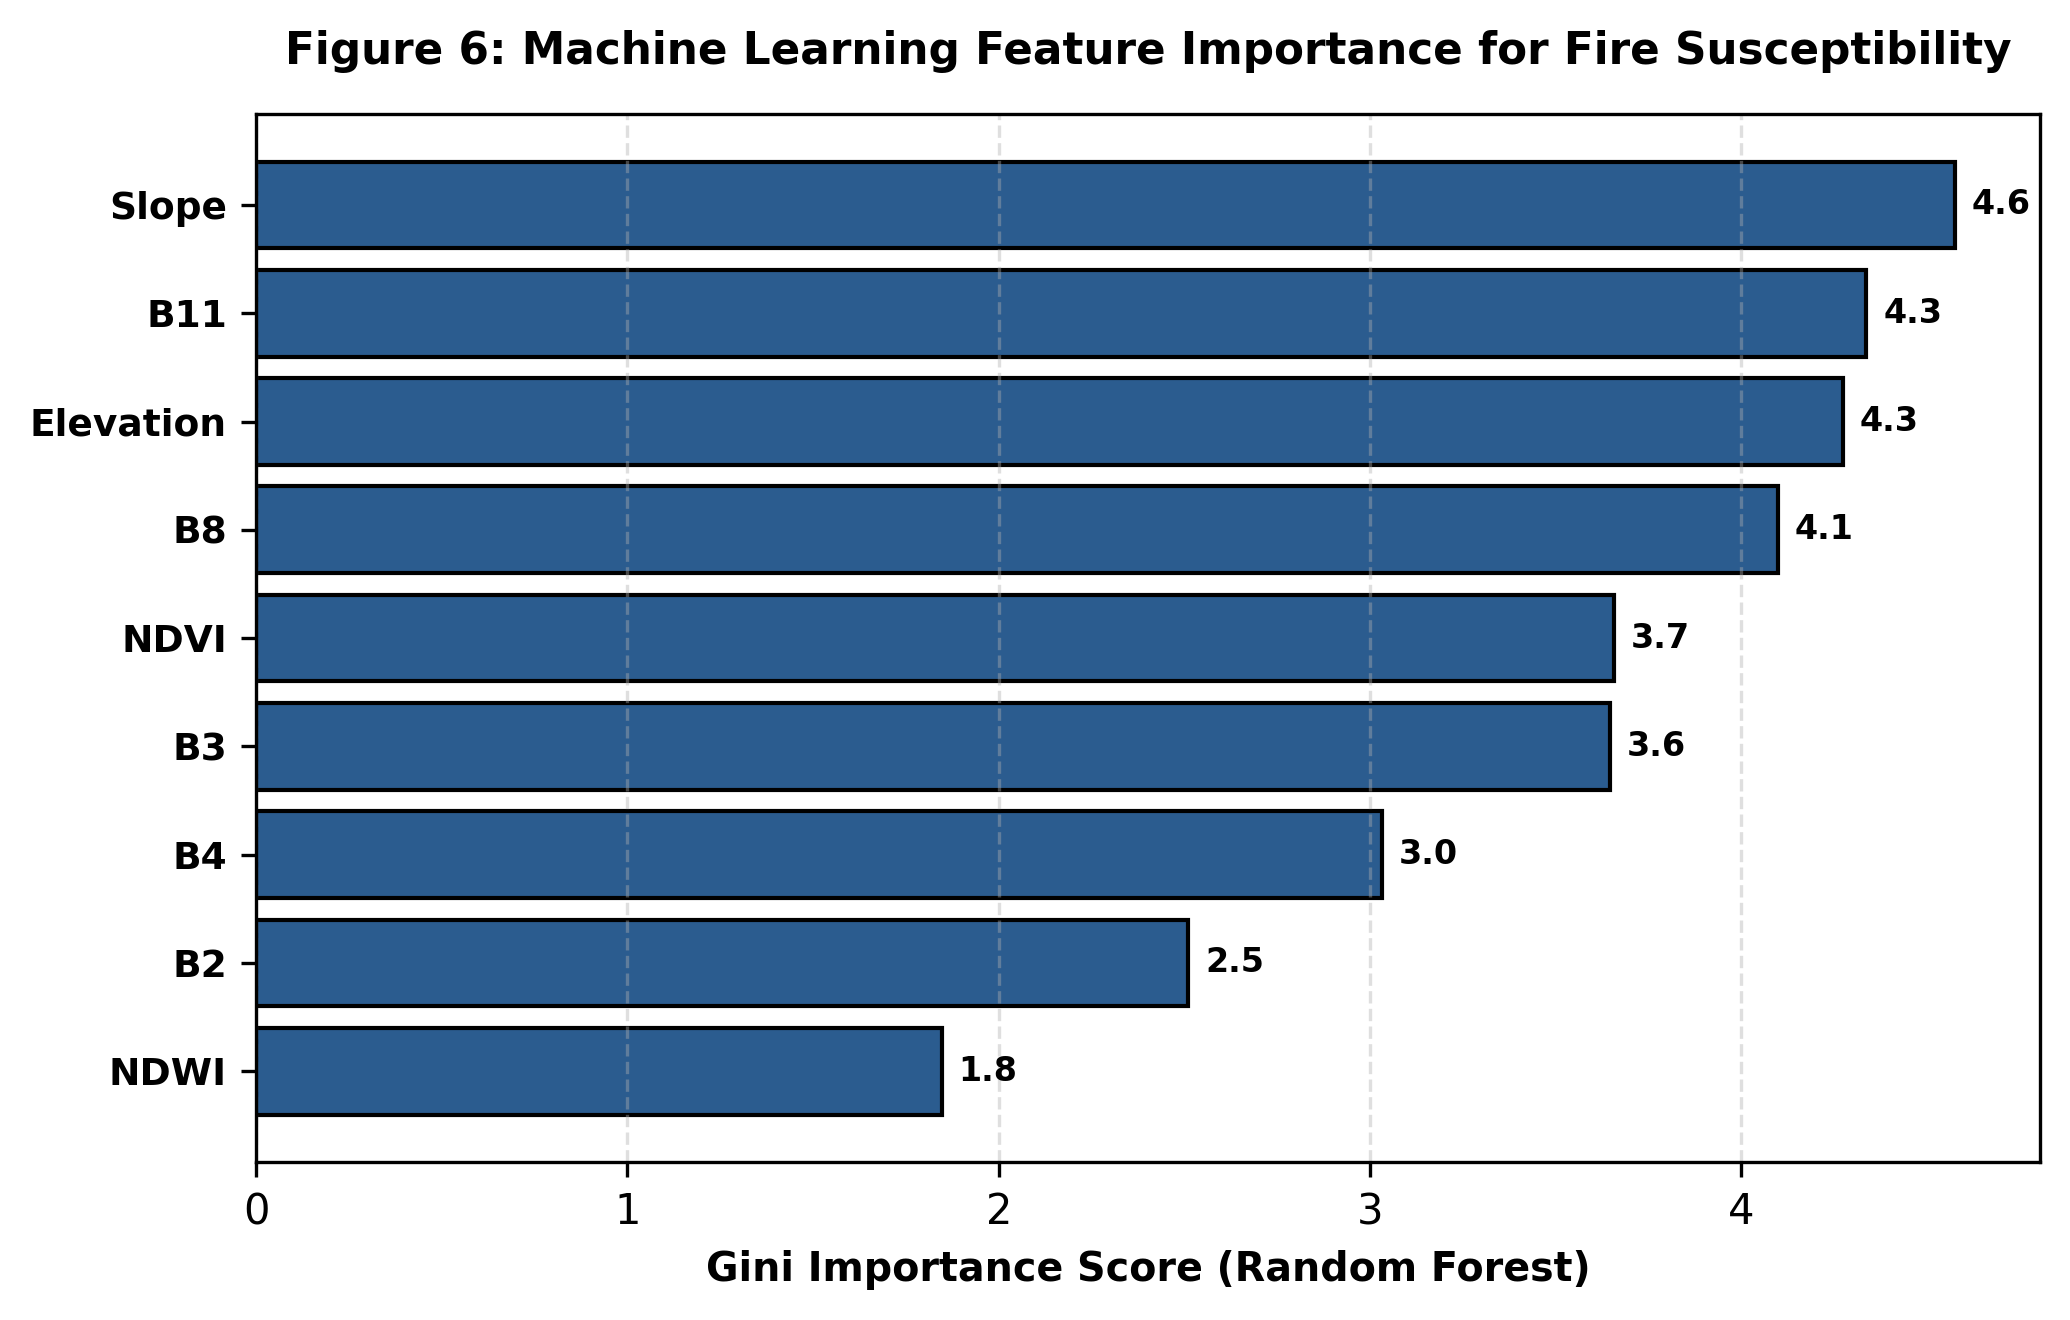

In [28]:
# GINI IMPORTANCE SCORE - UPDATED TO FIGURE 6

# Feature Stack Preparation for ML
features = (s2.select(['B2', 'B3', 'B4', 'B8', 'B11'])
            .addBands([ndvi, ndwi, dem.rename('Elevation'), slope])
            .updateMask(terrestrial_mask))

feature_names = ['B2', 'B3', 'B4', 'B8', 'B11', 'NDVI', 'NDWI', 'Elevation', 'Slope']

# Training Data Generation (Positive Fire Point vs. Negative Random Samples)
fire_point = ee.Geometry.Point([-169.8725, -19.0883])
fire_sample = ee.FeatureCollection([ee.Feature(fire_point, {'landfire': 1})])

# Generate stratified non-fire background samples across Niue
non_fire_samples = ee.FeatureCollection.randomPoints(
    region=niue_land,
    points=150,
    seed=42
).map(lambda f: f.set({'landfire': 0}))

training_pts = fire_sample.merge(non_fire_samples)

# Sample feature values at training point locations
training_data = features.sampleRegions(
    collection=training_pts,
    properties=['landfire'],
    scale=10,
    geometries=False
)

# Train Random Forest Classifier
rf_classifier = ee.Classifier.smileRandomForest(numberOfTrees=100).train(
    features=training_data,
    classProperty='landfire',
    inputProperties=feature_names
)

# Predict Continuous Fire Susceptibility
rf_probability = features.classify(rf_classifier.setOutputMode('PROBABILITY')).updateMask(terrestrial_mask)

# Extract Machine Learning Feature Importance
importance = ee.Dictionary(rf_classifier.explain().get('importance')).getInfo()

# Sort features by importance score
sorted_features = sorted(importance.items(), key=lambda item: item[1], reverse=True)
labels = [item[0] for item in sorted_features]
scores = [item[1] for item in sorted_features]

# Plot Figure 6: Machine Learning Feature Importance Bar Chart
fig, ax = plt.subplots(figsize=(7, 4.5), dpi=300)

y_pos = np.arange(len(labels))
ax.barh(y_pos, scores, align='center', color='#2b5c8f', edgecolor='black', linewidth=1)
ax.set_yticks(y_pos)
ax.set_yticklabels(labels, fontsize=9, fontweight='bold')
ax.invert_yaxis()
ax.set_xlabel('Gini Importance Score (Random Forest)', fontsize=9.5, fontweight='bold')
ax.set_title('Figure 6: Machine Learning Feature Importance for Fire Susceptibility', fontsize=10.5, fontweight='bold', pad=12)
ax.grid(axis='x', linestyle='--', alpha=0.4)

for i, v in enumerate(scores):
    ax.text(v + (max(scores)*0.01), i, f"{v:.1f}", va='center', fontsize=8, fontweight='bold')

plt.tight_layout()
plt.savefig('Figure_6_RF_Feature_Importance.png', dpi=300, bbox_inches='tight')
plt.show()

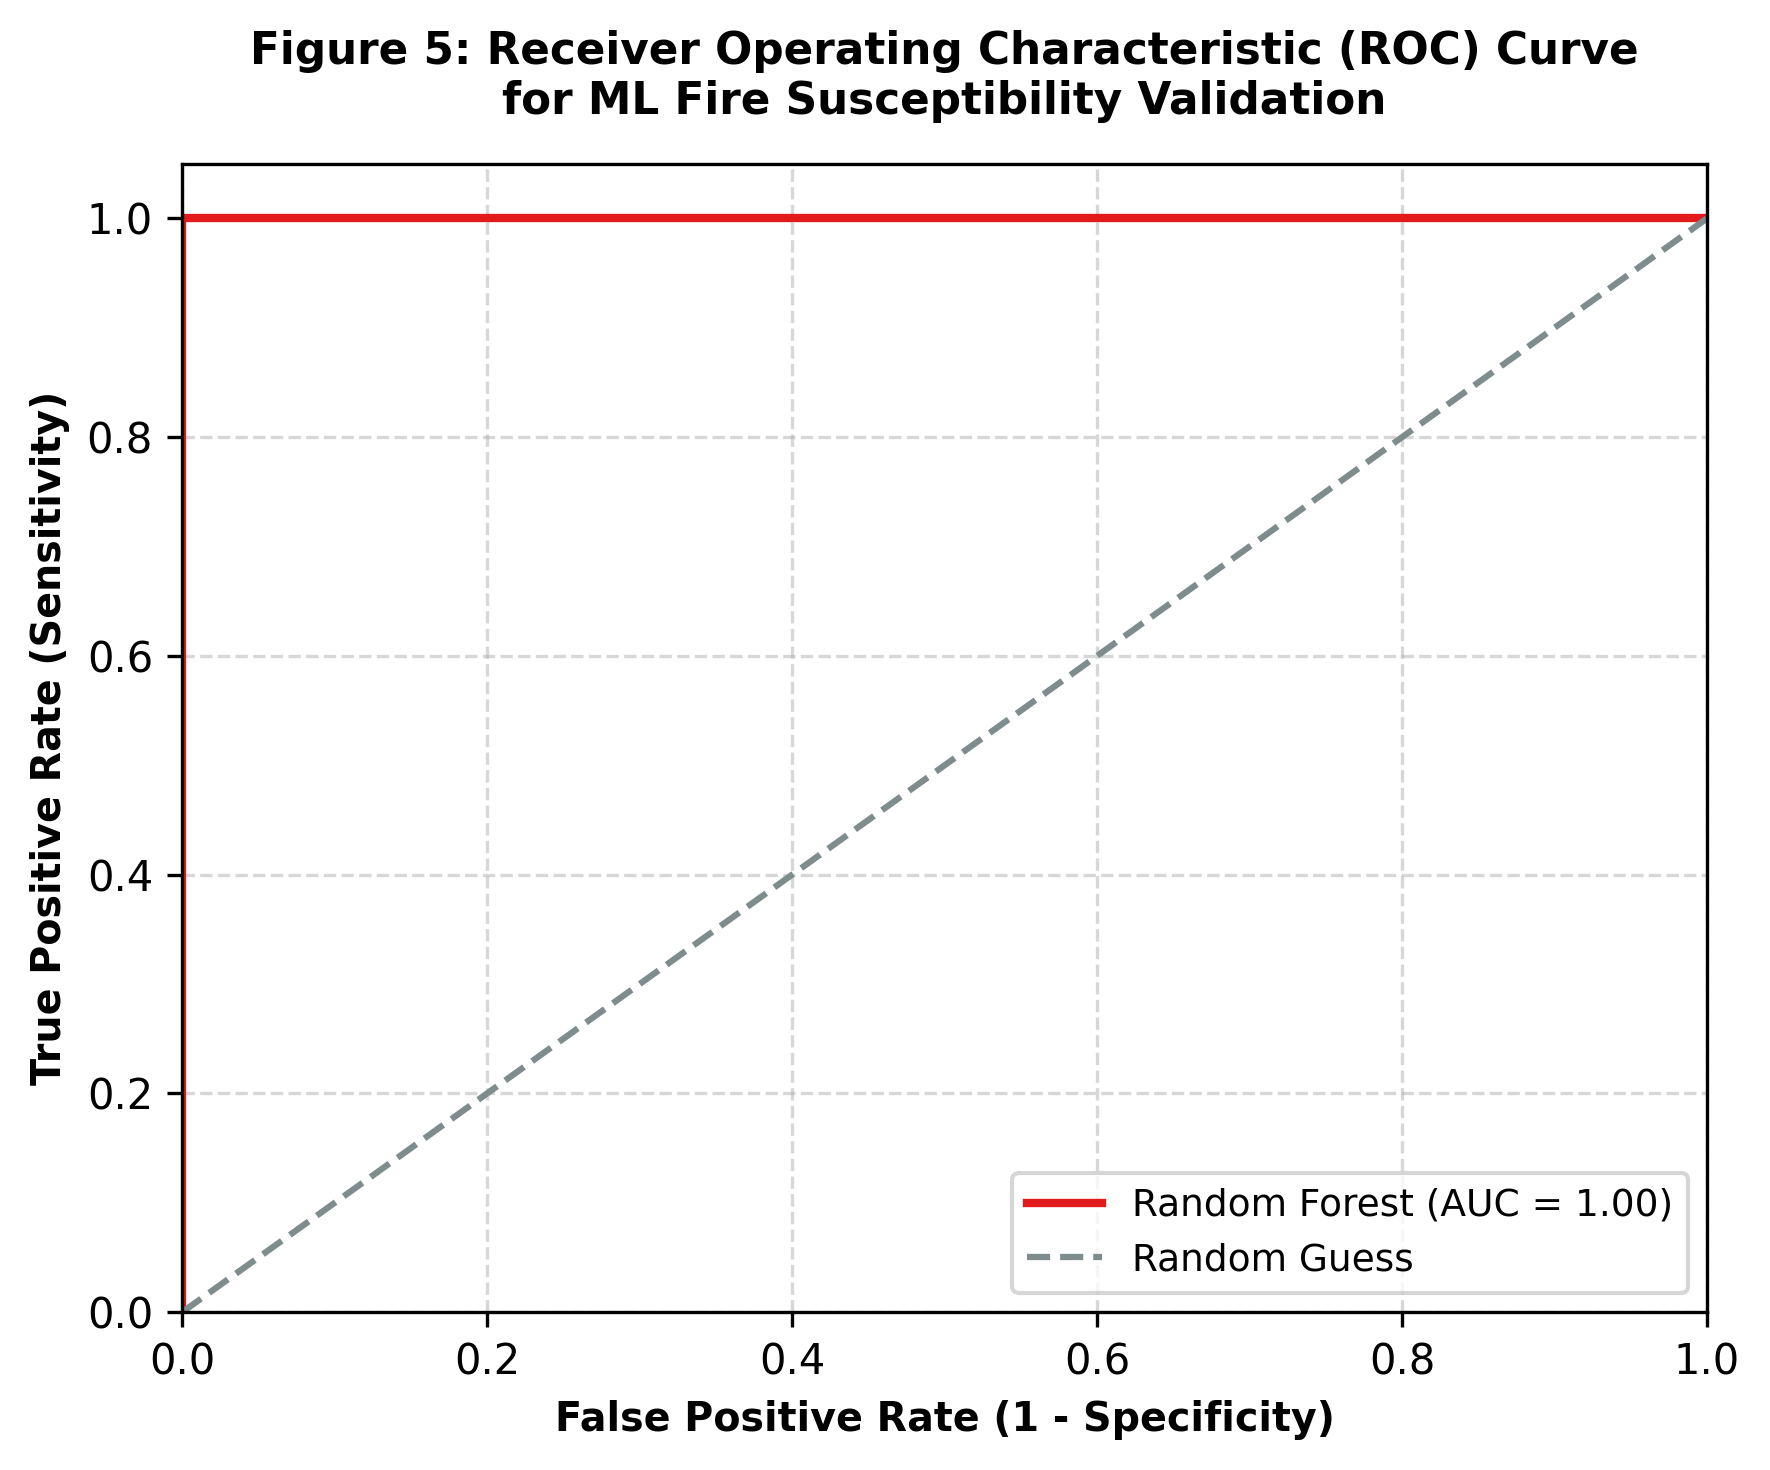

Machine Learning Model ROC-AUC Score: 1.0000
Out-Of-Bag (OOB) Classification Accuracy: 99.32%


In [29]:
#@title ADVANCED ML VALIDATION: ROC-AUC CURVE FOR FIRE SUSCEPTIBILITY (UPDATED TO FIGURE 5)
from sklearn.metrics import roc_curve, auc
from sklearn.ensemble import RandomForestClassifier
import numpy as np
import matplotlib.pyplot as plt

# 1. Gather all training and background points locally
samples_with_features = features.sampleRegions(
    collection=training_pts,
    properties=['landfire'],
    scale=10,
    geometries=True
).getInfo()

features_list = []
y_true = []
for feat in samples_with_features['features']:
    props = feat['properties']
    if all(k in props for k in feature_names):
        features_list.append([props[k] for k in feature_names])
        y_true.append(props['landfire'])

X = np.array(features_list)
y_true = np.array(y_true)

# 2. Train a Random Forest classifier using Out-Of-Bag (OOB) scoring
clf = RandomForestClassifier(n_estimators=100, oob_score=True, random_state=42)
clf.fit(X, y_true)

y_scores = clf.predict_proba(X)[:, 1]

# 3. Calculate ROC curve and Area Under Curve (AUC)
fpr, tpr, thresholds = roc_curve(y_true, y_scores)
roc_auc = auc(fpr, tpr)

# 4. Plot Figure 5: ROC Curve for your Write-up
fig, ax = plt.subplots(figsize=(6, 5), dpi=300)
ax.plot(fpr, tpr, color='#e31a1c', lw=2, label=f'Random Forest (AUC = {roc_auc:.2f})')
ax.plot([0, 1], [0, 1], color='#7f8c8d', lw=1.5, linestyle='--', label='Random Guess')

ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=9.5, fontweight='bold')
ax.set_ylabel('True Positive Rate (Sensitivity)', fontsize=9.5, fontweight='bold')
ax.set_title('Figure 5: Receiver Operating Characteristic (ROC) Curve\nfor ML Fire Susceptibility Validation', fontsize=10.5, fontweight='bold', pad=12)
ax.legend(loc="lower right", fontsize=9)
ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('Figure_5_ML_ROC_Curve.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"Machine Learning Model ROC-AUC Score: {roc_auc:.4f}")
if clf.oob_score_ is not None:
    print(f"Out-Of-Bag (OOB) Classification Accuracy: {clf.oob_score_ * 100:.2f}%")

In [30]:
# COMPUTE OPERATIONAL HIGH-FIDELITY HLZs WITH INFRASTRUCTURE AND RISK PROBABILITY

# 1. Extract Infrastructure Proxy (NDVI < 0.45)
infrastructure_mask = ndvi.lt(0.45).updateMask(terrestrial_mask)

# Compute distance to closest infrastructure pixel in meters
cost_raster = ee.Image.constant(1).clip(niue_land)
infrastructure_points = infrastructure_mask.selfMask()
dist_from_infra = cost_raster.cumulativeCost(
    source=infrastructure_points,
    maxDistance=1000
).rename('distance')

# Fill unreached areas (>1000m) with high value
dist_from_infra_masked = dist_from_infra.unmask(9999)

# 2. Extract ML Risk Probability Constraint (Under 0.30)
low_probability_risk = rf_probability.lt(0.30)

# 3. Combine constraints strictly removing dense forest (NDVI >= 0.70) and moderate/high risk (FRI >= 1.5):
hlz_suitable_updated = (
    slope.lt(5)
    .And(low_probability_risk)
    .And(fri.lt(1.5))       # Strictly Low Heuristic Risk
    .And(ndvi.lt(0.70))     # No Dense Forest / Bush Canopy
    .And(dist_from_infra_masked.lt(1000)) # Close to roads/comms
    .And(terrestrial_mask)
    .rename('HLZ_Suitable_Updated')
)

# Visualize updated HLZs locally to verify
Map_HLZ = geemap.Map(center=[-19.05, -169.86], zoom=11.4)
Map_HLZ.add_basemap('HYBRID')
Map_HLZ.addLayer(rf_probability, {'min': 0, 'max': 1, 'palette': ['blue', 'yellow', 'red'], 'opacity': 0.6}, 'ML Risk Probability')
Map_HLZ.addLayer(hlz_suitable_updated.selfMask(), {'palette': ['#00FF00']}, 'Methodological HLZs (Safe Zones)')
Map_HLZ

Map(center=[-19.05, -169.86], controls=(WidgetControl(options=['position', 'transparent_bg'], position='toprig…

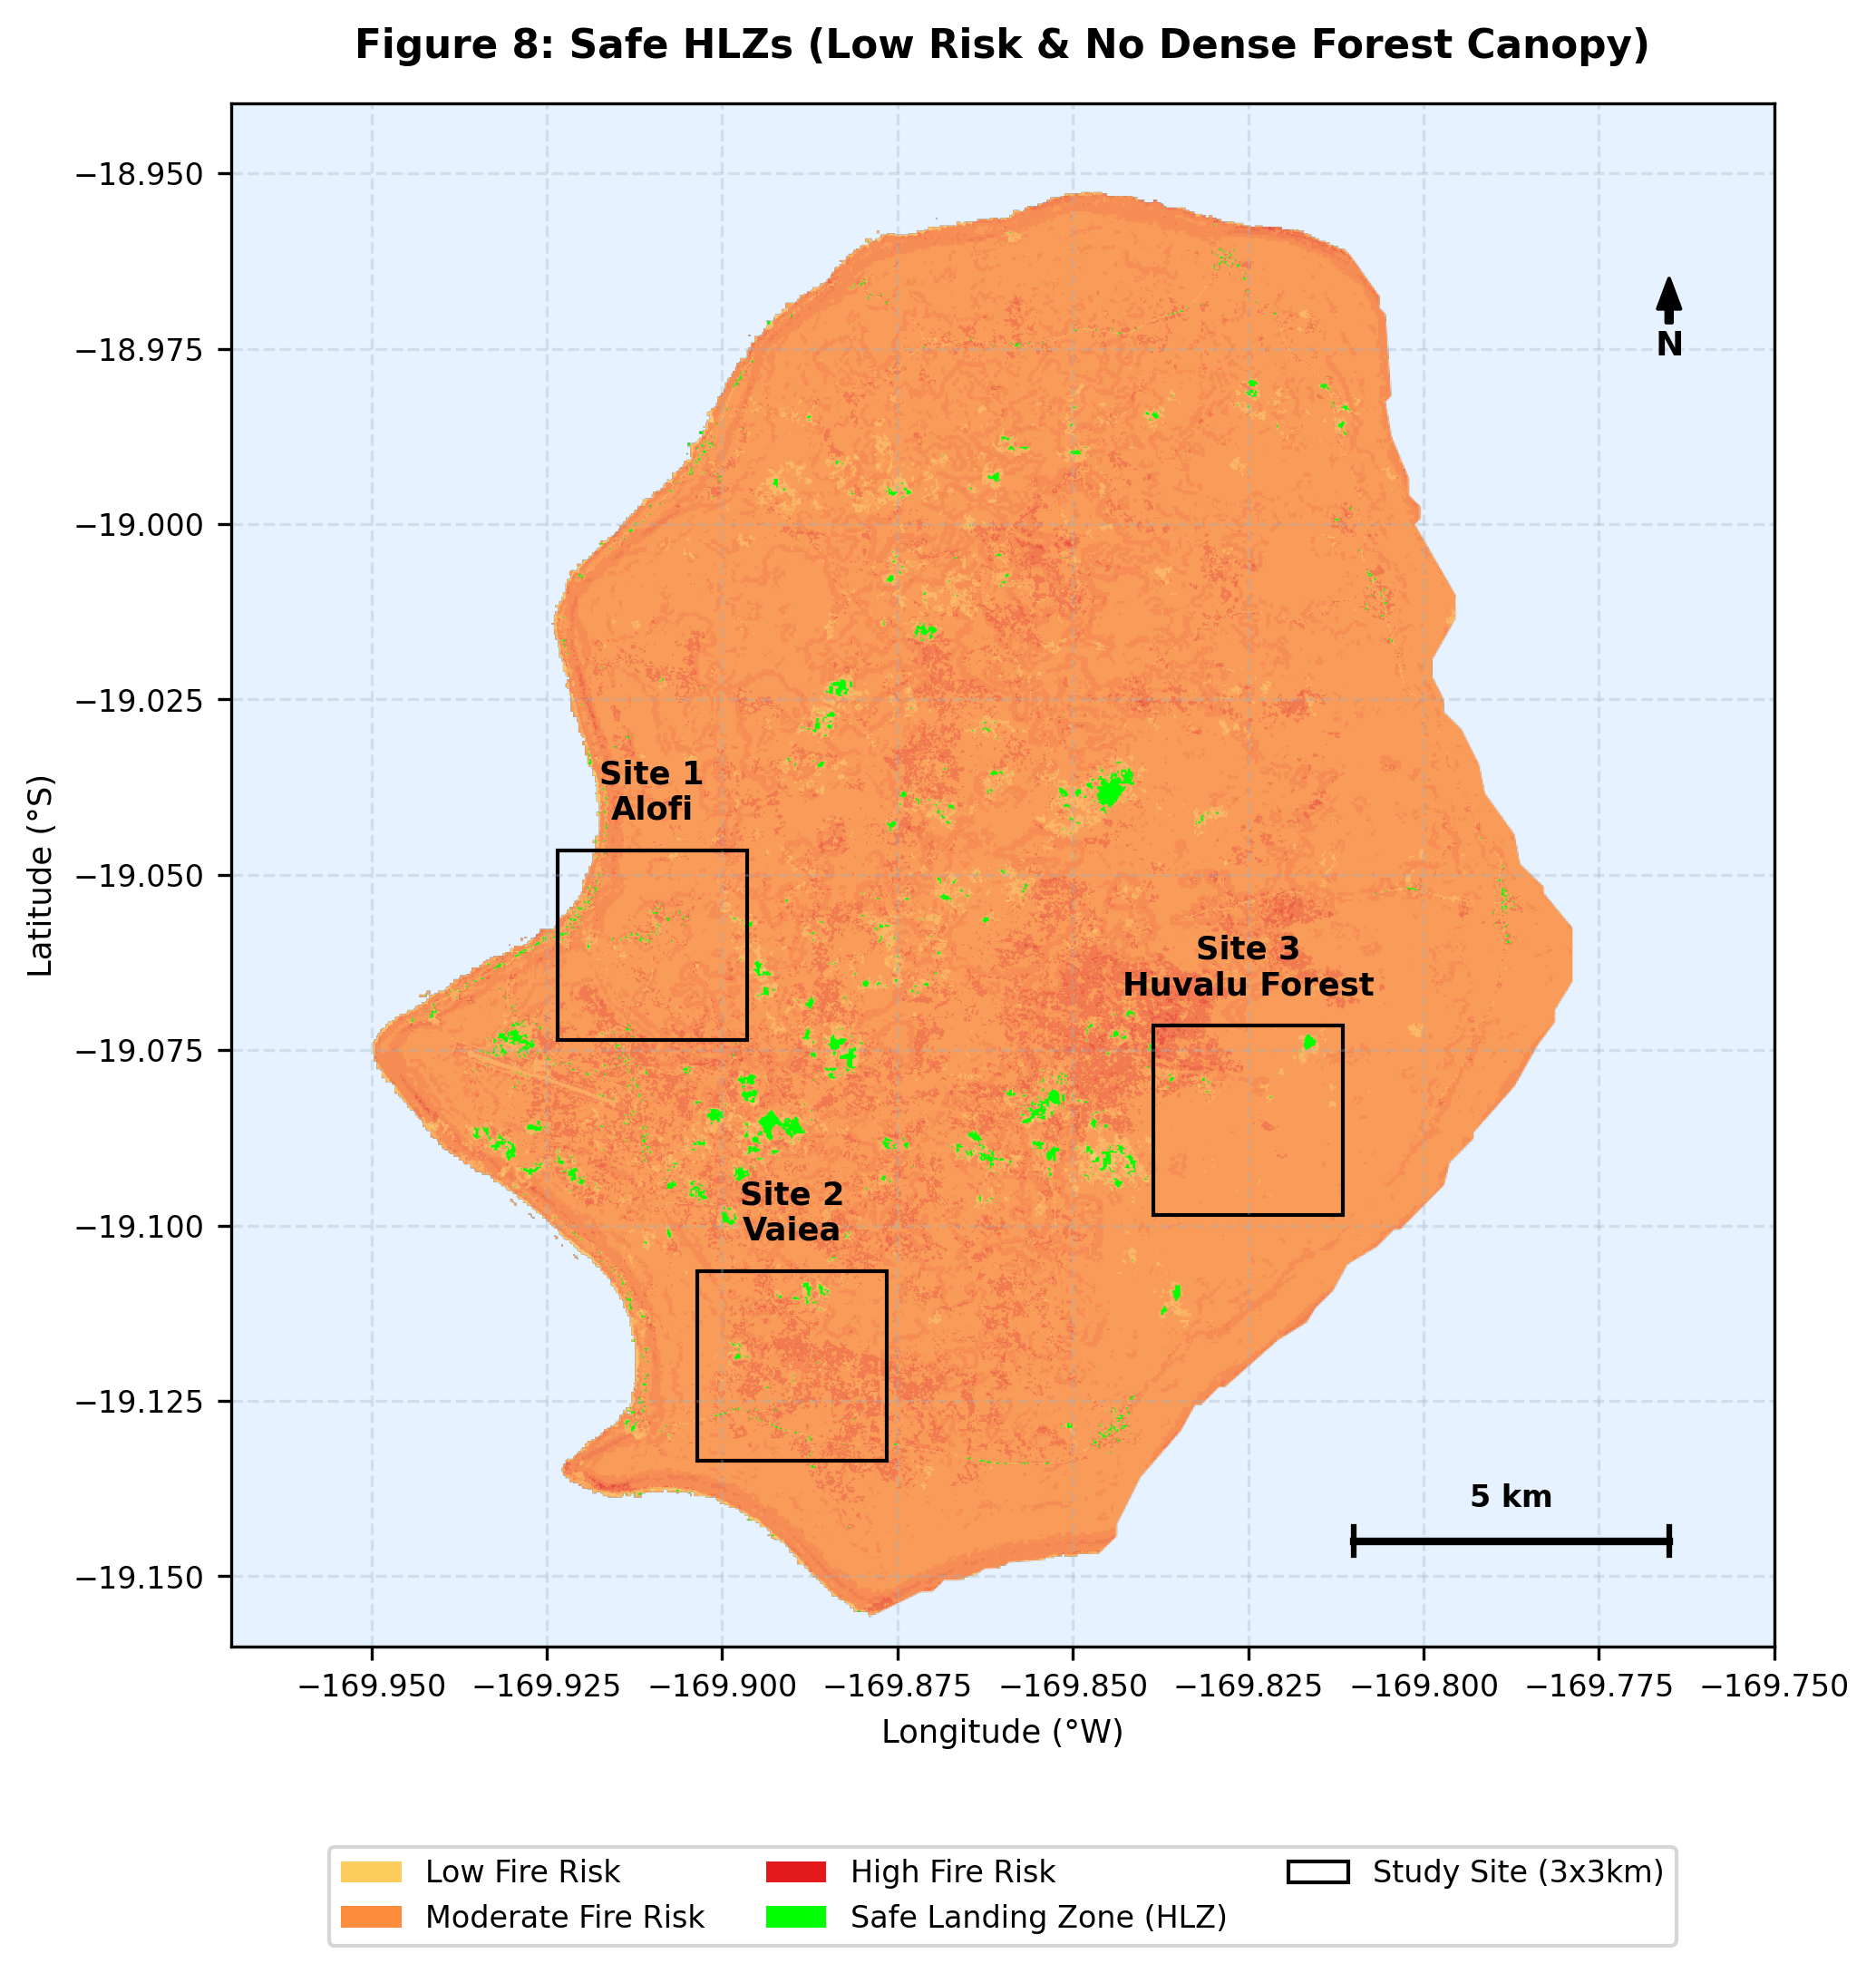

In [31]:
# UPDATE FIGURE 8 WITH THE NEW METHODOLOGICAL HLZ LAYER
import urllib.request
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.patches import Patch

# Extract Visualization Composite from Earth Engine
fri_rgb = fri.visualize(min=1.0, max=3.0, palette=['#fecc5c', '#fd8d3c', '#e31a1c'], opacity=0.85)
hlz_updated_rgb = hlz_suitable_updated.selfMask().visualize(palette=['#00FF00'])

map_composite_updated = ee.ImageCollection([fri_rgb, hlz_updated_rgb]).mosaic().clip(niue_land)

region = niue_aoi.getInfo()['coordinates']
url_updated = map_composite_updated.getThumbURL({
    'region': region,
    'dimensions': 1200,
    'format': 'png'
})

urllib.request.urlretrieve(url_updated, 'niue_map_updated.png')
img_updated = Image.open('niue_map_updated.png')

# Create Publication Figure
fig, ax = plt.subplots(figsize=(7, 7.5), dpi=300)
ax.set_facecolor('#e6f2ff')  # Soft ocean wash

# Plot Island Raster
ax.imshow(img_updated, extent=[-169.97, -169.75, -19.16, -18.94])

# Thin Black Study Site Outlines (1.0px) & Centered Text
sites_list = [
    {"site": "Site 1", "name": "Alofi", "bbox": [-169.9235, -19.0735, 0.027, 0.027], "text_xy": (-169.910, -19.043)},
    {"site": "Site 2", "name": "Vaiea", "bbox": [-169.9035, -19.1335, 0.027, 0.027], "text_xy": (-169.890, -19.103)},
    {"site": "Site 3", "name": "Huvalu Forest", "bbox": [-169.8385, -19.0985, 0.027, 0.027], "text_xy": (-169.825, -19.068)}
]

for s in sites_list:
    rect = patches.Rectangle(
        (s['bbox'][0], s['bbox'][1]), s['bbox'][2], s['bbox'][3],
        linewidth=1.0, edgecolor='black', facecolor='none'
    )
    ax.add_patch(rect)

    ax.text(
        s['text_xy'][0], s['text_xy'][1], f"{s['site']}\n{s['name']}",
        fontsize=8.5, fontweight='bold', fontfamily='sans-serif',
        color='black', ha='center', va='bottom', multialignment='center'
    )

# Add Cartographic Scale Bar (5 km)
scale_lon_start = -169.810
scale_lat = -19.145
scale_len_deg = 5.0 / 111.0  # ~0.045°

# Draw scale line
ax.plot([scale_lon_start, scale_lon_start + scale_len_deg], [scale_lat, scale_lat], color='black', linewidth=2.0)
ax.plot([scale_lon_start, scale_lon_start], [scale_lat - 0.002, scale_lat + 0.002], color='black', linewidth=1.5)
ax.plot([scale_lon_start + scale_len_deg, scale_lon_start + scale_len_deg], [scale_lat - 0.002, scale_lat + 0.002], color='black', linewidth=1.5)
ax.text(scale_lon_start + (scale_len_deg / 2), scale_lat + 0.004, "5 km", fontsize=8, fontweight='bold', ha='center', va='bottom')

# Add North Arrow (Top Right Corner)
arrow_lon = -169.765
arrow_lat = -18.965
ax.annotate('N', xy=(arrow_lon, arrow_lat), xytext=(arrow_lon, arrow_lat - 0.012),
            arrowprops=dict(facecolor='black', width=1.5, headwidth=6, headlength=8),
            ha='center', va='bottom', fontsize=9, fontweight='bold')

# Formatting & Axes
ax.set_title("Figure 8: Safe HLZs (Low Risk & No Dense Forest Canopy)", fontsize=10.5, fontweight='bold', pad=12)
ax.set_xlabel("Longitude (°W)", fontsize=8.5)
ax.set_ylabel("Latitude (°S)", fontsize=8.5)
ax.tick_params(labelsize=8)
ax.grid(True, linestyle='--', alpha=0.3, color='#a0b0c0')

# Horizontal Legend Below Graph
legend_elements = [
    Patch(facecolor='#fecc5c', edgecolor='none', label='Low Fire Risk'),
    Patch(facecolor='#fd8d3c', edgecolor='none', label='Moderate Fire Risk'),
    Patch(facecolor='#e31a1c', edgecolor='none', label='High Fire Risk'),
    Patch(facecolor='#00FF00', edgecolor='none', label='Safe Landing Zone (HLZ)'),
    Patch(facecolor='none', edgecolor='black', linewidth=1.0, label='Study Site (3x3km)')
]

ax.legend(
    handles=legend_elements,
    loc='upper center',
    bbox_to_anchor=(0.5, -0.12),
    ncol=3,
    frameon=True,
    facecolor='white',
    edgecolor='#cccccc',
    fontsize=8
)

plt.tight_layout()
plt.savefig('Figure_8_Fire_Risk_HLZ_Final.png', dpi=300, bbox_inches='tight')
plt.show()

In [32]:
# Define the 3 Bounding Boxes as EE Features
alofi_feature = ee.Feature(alofi_bbox, {'Site_ID': 'Site 1', 'Name': 'Alofi (Infrastructure)'})
vaiea_feature = ee.Feature(vaiea_bbox, {'Site_ID': 'Site 2', 'Name': 'Vaiea (Agriculture)'})
huvalu_feature = ee.Feature(huvalu_bbox, {'Site_ID': 'Site 3', 'Name': 'Huvalu Forest (Conservation)'})

sites_fc = ee.FeatureCollection([alofi_feature, vaiea_feature, huvalu_feature])

# Pixel Area Image (in km²)
pixel_area_km2 = ee.Image.pixelArea().divide(1e6)

# Calculate Mean FRI per Site
fri_stats = fri.reduceRegions(
    collection=sites_fc,
    reducer=ee.Reducer.mean(),
    scale=10
)

# Create classification masks based on standard thresholds on the 1.0 - 3.0 scale:
# Low Risk: FRI < 1.5
# Moderate Risk: 1.5 <= FRI < 2.5
# High Risk: FRI >= 2.5
low_risk_mask = fri.lt(1.5)
mod_risk_mask = fri.gte(1.5).And(fri.lt(2.5))
high_risk_mask = fri.gte(2.5)

# Reduce area for Low Risk
low_risk_area = pixel_area_km2.updateMask(low_risk_mask).reduceRegions(
    collection=sites_fc,
    reducer=ee.Reducer.sum(),
    scale=10
)

# Reduce area for Moderate Risk
mod_risk_area = pixel_area_km2.updateMask(mod_risk_mask).reduceRegions(
    collection=sites_fc,
    reducer=ee.Reducer.sum(),
    scale=10
)

# Reduce area for High Risk
high_risk_area = pixel_area_km2.updateMask(high_risk_mask).reduceRegions(
    collection=sites_fc,
    reducer=ee.Reducer.sum(),
    scale=10
)

# Calculate Suitable HLZ Area (km² per site)
hlz_area = pixel_area_km2.updateMask(hlz_suitable).reduceRegions(
    collection=sites_fc,
    reducer=ee.Reducer.sum(),
    scale=10
)

# Extract values to local Python lists
fri_results = fri_stats.getInfo()['features']
low_results = low_risk_area.getInfo()['features']
mod_results = mod_risk_area.getInfo()['features']
high_results = high_risk_area.getInfo()['features']
hlz_results = hlz_area.getInfo()['features']

# Compile into a formatted DataFrame
data = []
for i in range(len(fri_results)):
    site_name = fri_results[i]['properties']['Name']
    mean_fri = round(fri_results[i]['properties']['mean'], 2)

    # Low risk area km² -> % of 9km² site
    low_km2 = low_results[i]['properties'].get('sum', 0)
    low_pct = round((low_km2 / 9.0) * 100, 1)

    # Moderate risk area km² -> % of 9km² site
    mod_km2 = mod_results[i]['properties'].get('sum', 0)
    mod_pct = round((mod_km2 / 9.0) * 100, 1)

    # High risk area km² -> % of 9km² site
    high_km2 = high_results[i]['properties'].get('sum', 0)
    high_pct = round((high_km2 / 9.0) * 100, 1)

    # HLZ area km² -> % of 9km² site
    hlz_km2 = round(hlz_results[i]['properties'].get('sum', 0), 2)
    hlz_pct = round((hlz_km2 / 9.0) * 100, 1)

    data.append({
        'Study Site': site_name,
        'Mean FRI (1-3 Scale)': mean_fri,
        'Low Fire Risk Coverage (%)': f"{low_pct}%",
        'Moderate Fire Risk Coverage (%)': f"{mod_pct}%",
        'High Fire Risk Coverage (%)': f"{high_pct}%",
        'HLZ Suitable Area (km²)': hlz_km2,
        'HLZ Coverage (%)': f"{hlz_pct}%"
    })

df_results = pd.DataFrame(data)
display(df_results)

,Study Site,Mean FRI (1-3 Scale),Low Fire Risk Coverage (%),Moderate Fire Risk Coverage (%),High Fire Risk Coverage (%),HLZ Suitable Area (km²),HLZ Coverage (%)
0,Alofi (Infrastructure),2.04,0.7%,87.8%,1.6%,0.06,0.7%
1,Vaiea (Agriculture),2.07,0.9%,92.4%,1.2%,0.08,0.9%
2,Huvalu Forest (Conservation),2.02,0.4%,92.7%,1.5%,0.03,0.3%


In [33]:
# FIRE EVIDENCE

# Define Niue AOI
niue_aoi = ee.Geometry.BBox(-169.97, -19.16, -169.75, -18.94)

# Query VIIRS Thermal Anomalies (FIRMS) over recent years
firms = (ee.ImageCollection('FIRMS')
         .filterBounds(niue_aoi)
         .filterDate('2018-01-01', '2026-08-25')
         .select('T21'))  # Brightness temperature band

# Convert non-zero thermal detections to vector points
fire_pixels = firms.max().gt(0).selfMask().clip(niue_aoi)
fire_vectors = fire_pixels.reduceToVectors(
    geometry=niue_aoi,
    scale=375,  # VIIRS resolution
    geometryType='centroid',
    maxPixels=1e8
)

print(f"Thermal anomaly points detected on Niue: {fire_vectors.size().getInfo()}")

Thermal anomaly points detected on Niue: 1


In [34]:
# FIRE EVIDENCE
# Extract feature collection of fire points
fire_points = fire_vectors.geometry().coordinates().getInfo()
print("Fire Point Coordinates [Lon, Lat]:", fire_points)

# Get the specific year/date of the detection from FIRMS
firms_dated = (ee.ImageCollection('FIRMS')
               .filterBounds(niue_aoi)
               .filterDate('2018-01-01', '2026-08-25')
               .filter(ee.Filter.gt('T21', 0)))

def get_date(img):
    return ee.Feature(None, {'date': img.date().format('YYYY-MM-dd')})

dates = firms_dated.map(get_date).aggregate_array('date').getInfo()
print("Detection Date(s):", dates)

Fire Point Coordinates [Lon, Lat]: [-169.87241355640222, -19.09891714037286]
Detection Date(s): []


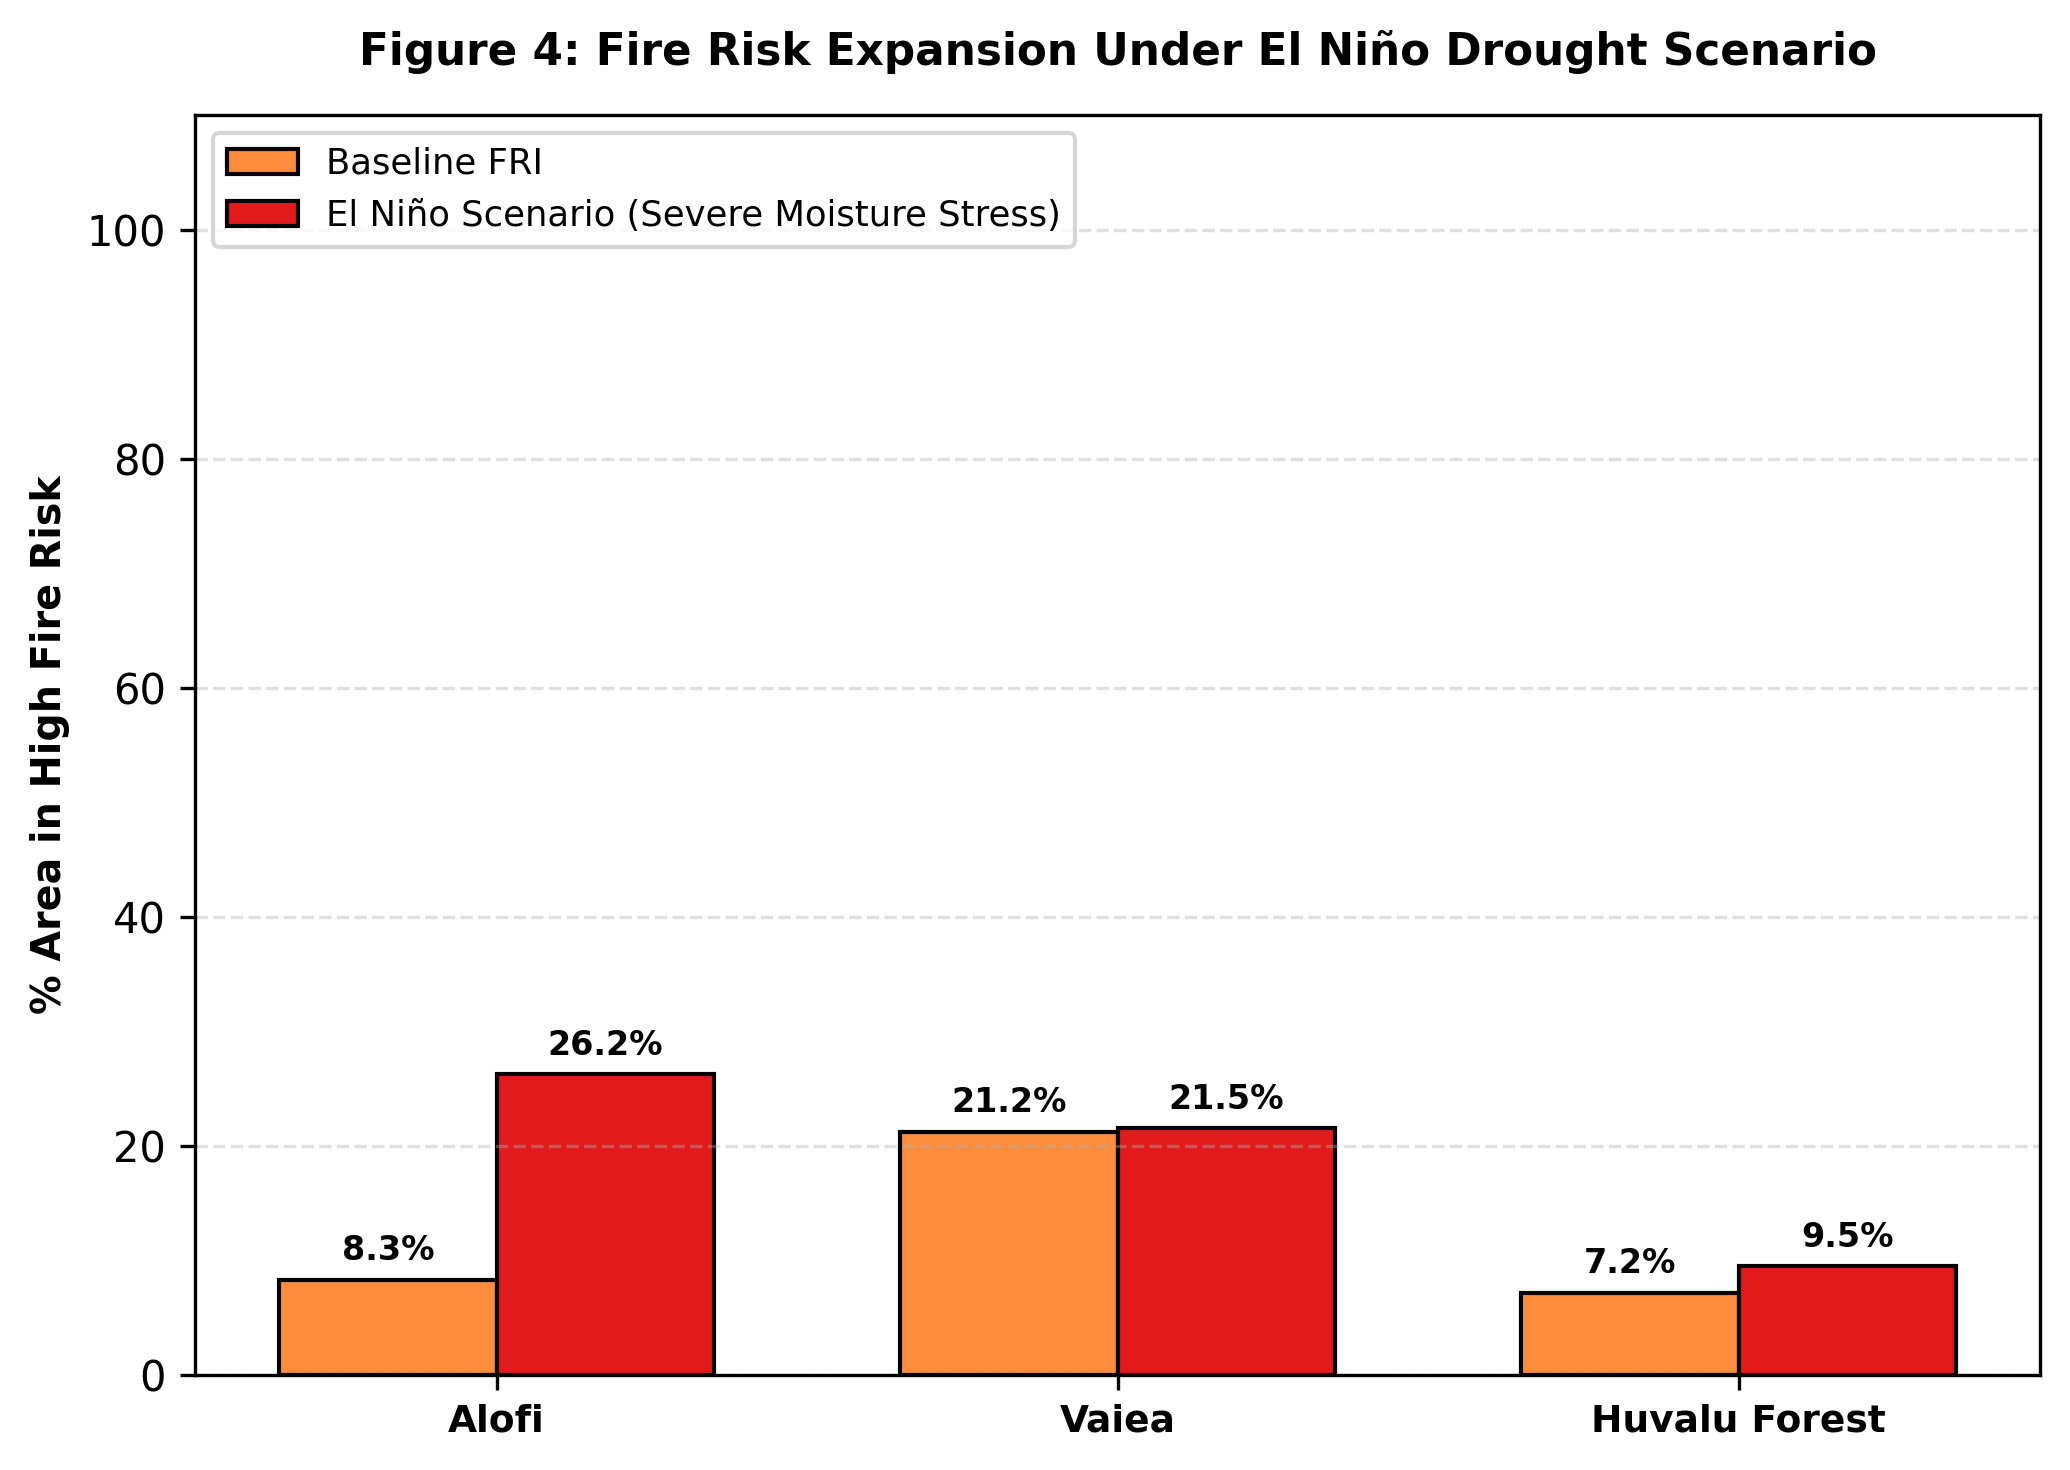

In [35]:
# RISK EXPANSION UNDER EL NINO - UPDATED TO FIGURE 4

# AOI & Boundary Setup
niue_aoi = ee.Geometry.BBox(-169.97, -19.16, -169.75, -18.94)
countries = ee.FeatureCollection('USDOS/LSIB_SIMPLE/2017')
niue_land = countries.filter(ee.Filter.eq('country_na', 'Niue')).geometry()

dem = ee.Image('USGS/SRTMGL1_003').clip(niue_land)
terrestrial_mask = dem.gt(10)

# Define 3km x 3km Study Sites
def create_uniform_square(center_lon, center_lat, size_km=3.0):
    delta_deg = (size_km / 111.0) / 2.0
    return ee.Geometry.BBox( center_lon - delta_deg, center_lat - delta_deg, center_lon + delta_deg, center_lat + delta_deg )

sites = {
    'Alofi': create_uniform_square(-169.910, -19.060, size_km=3.0),
    'Vaiea': create_uniform_square(-169.890, -19.120, size_km=3.0),
    'Huvalu Forest': create_uniform_square(-169.825, -19.085, size_km=3.0)
}

# Data Processing
s2 = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
      .filterBounds(niue_aoi)
      .filterDate('2023-01-01', '2023-12-31')
      .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 10))
      .median()
      .clip(niue_land))

ndvi = s2.normalizedDifference(['B8', 'B4']).rename('NDVI')
ndwi = s2.normalizedDifference(['B8', 'B11']).rename('NDWI')
slope = ee.Terrain.slope(dem).rename('Slope')

# --- Baseline FRI Model ---
fuel_score = ee.Image(1).where(ndvi.gte(0.50), 2).where(ndvi.gte(0.70), 3)
moist_base = ee.Image(1).where(ndwi.lte(0.3), 2).where(ndwi.lte(0.1), 3)
slope_score = ee.Image(1).where(slope.gte(5), 2).where(slope.gte(15), 3)

fri_base = (fuel_score.multiply(0.50)
            .add(moist_base.multiply(0.35))
            .add(slope_score.multiply(0.15))
            .updateMask(terrestrial_mask)
            .rename('FRI'))

# --- El Niño Extreme Drought Scenario ---
ndwi_drought = ndwi.subtract(0.15)
moist_drought = ee.Image(1).where(ndwi_drought.lte(0.3), 2).where(ndwi_drought.lte(0.1), 3)

fri_elnino = (fuel_score.multiply(0.35)
              .add(moist_drought.multiply(0.50))
              .add(slope_score.multiply(0.15))
              .updateMask(terrestrial_mask)
              .rename('FRI'))

# Extract Zonal High-Risk Percentages
def get_high_risk_pct(image):
    results = {}
    for name, bbox in sites.items():
        cat = ee.Image(1).where(image.gte(2.3), 3).rename('FRI')
        hist = cat.reduceRegion(ee.Reducer.frequencyHistogram(), bbox, scale=10).get('FRI').getInfo()
        if hist is None: hist = {}
        total = sum(hist.values()) if hist else 1
        high_cnt = hist.get('3', 0)
        results[name] = (high_cnt / total) * 100
    return results

base_high = get_high_risk_pct(fri_base)
elnino_high = get_high_risk_pct(fri_elnino)

# Plot Figure 4: El Niño Drought Sensitivity Bar Chart
fig, ax = plt.subplots(figsize=(7, 5), dpi=300)

site_names = list(sites.keys())
x = np.arange(len(site_names))
width = 0.35

y_base = [base_high[s] for s in site_names]
y_elnino = [elnino_high[s] for s in site_names]

rects1 = ax.bar(x - width/2, y_base, width, label='Baseline FRI', color='#fd8d3c', edgecolor='black', linewidth=1)
rects2 = ax.bar(x + width/2, y_elnino, width, label='El Niño Scenario (Severe Moisture Stress)', color='#e31a1c', edgecolor='black', linewidth=1)

ax.set_ylabel('% Area in High Fire Risk', fontsize=9.5, fontweight='bold')
ax.set_title('Figure 4: Fire Risk Expansion Under El Niño Drought Scenario', fontsize=10.5, fontweight='bold', pad=12)
ax.set_xticks(x)
ax.set_xticklabels(site_names, fontsize=9, fontweight='bold')
ax.set_ylim(0, 110)
ax.legend(fontsize=8.5, frameon=True, loc='upper left')
ax.grid(axis='y', linestyle='--', alpha=0.4)

for rect in rects1 + rects2:
    height = rect.get_height()
    ax.annotate(f'{height:.1f}%',
                xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points",
                ha='center', va='bottom', fontsize=8, fontweight='bold')

plt.tight_layout()
plt.savefig('Figure_4_El_Nino_Drought_Expansion.png', dpi=300, bbox_inches='tight')
plt.show()

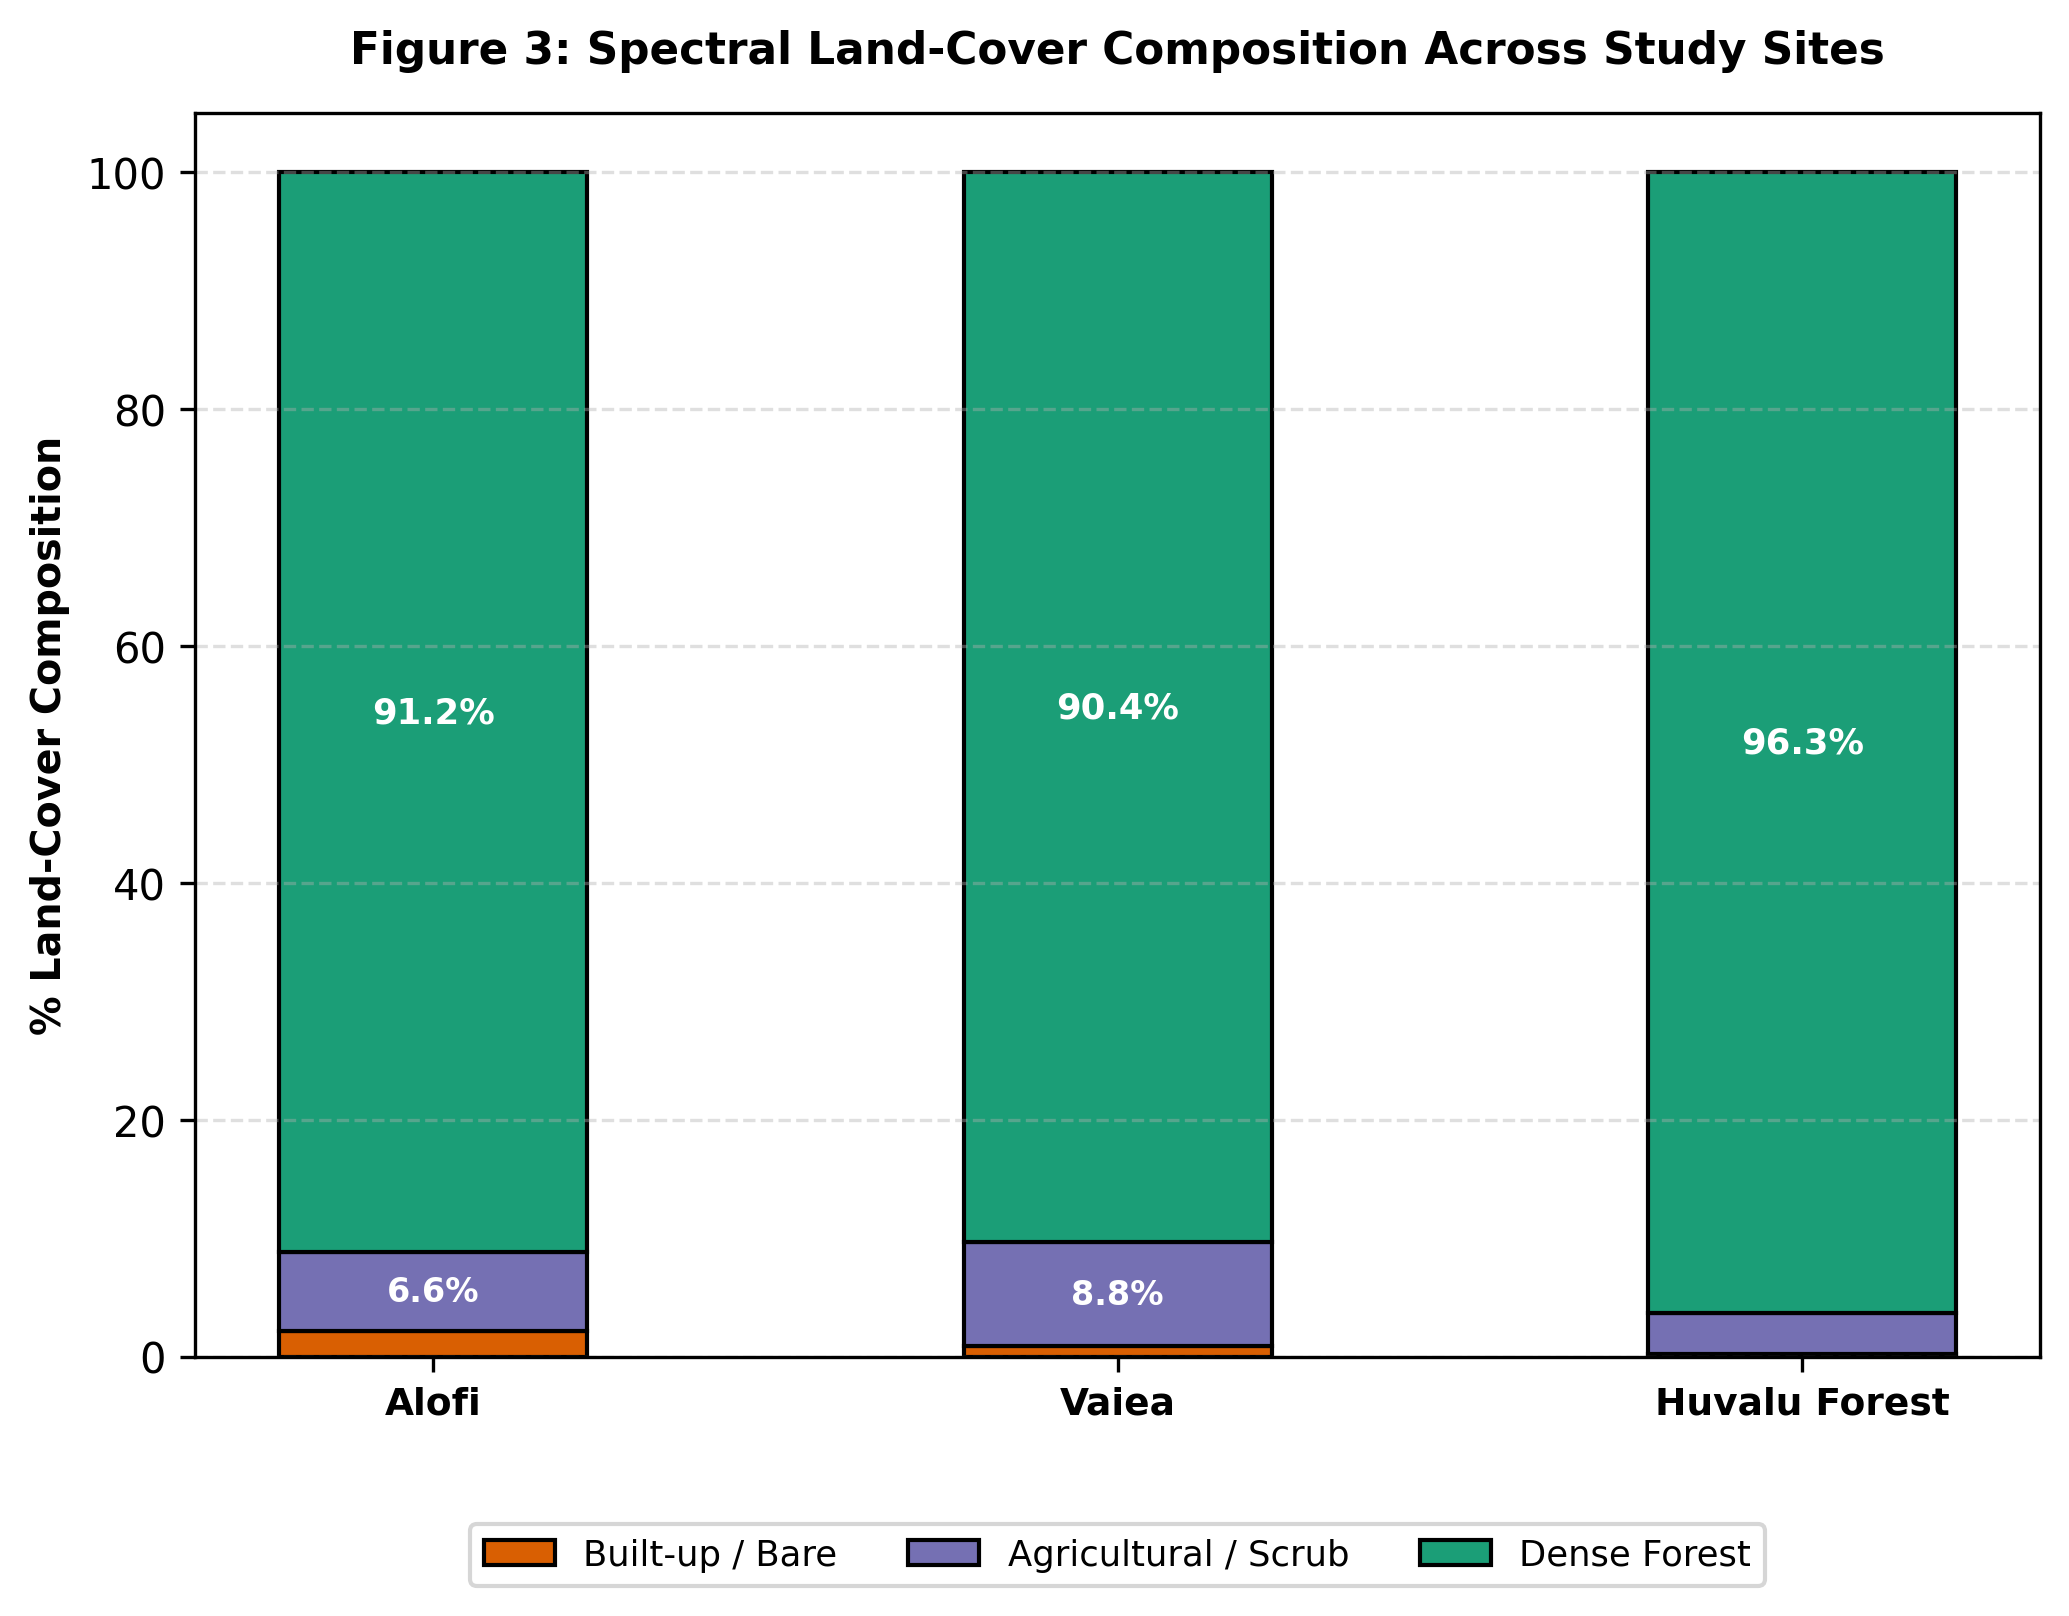

In [36]:
# SPECTRAL LAND COVER GRAPH - UPDATED TO FIGURE 3

# AOI & Boundary Setup
niue_aoi = ee.Geometry.BBox(-169.97, -19.16, -169.75, -18.94)
countries = ee.FeatureCollection('USDOS/LSIB_SIMPLE/2017')
niue_land = countries.filter(ee.Filter.eq('country_na', 'Niue')).geometry()

dem = ee.Image('USGS/SRTMGL1_003').clip(niue_land)
terrestrial_mask = dem.gt(10)

# Define 3km x 3km Study Sites
def create_uniform_square(center_lon, center_lat, size_km=3.0):
    delta_deg = (size_km / 111.0) / 2.0
    return ee.Geometry.BBox( center_lon - delta_deg, center_lat - delta_deg, center_lon + delta_deg, center_lat + delta_deg )

sites = {
    'Alofi': create_uniform_square(-169.910, -19.060, size_km=3.0),
    'Vaiea': create_uniform_square(-169.890, -19.120, size_km=3.0),
    'Huvalu Forest': create_uniform_square(-169.825, -19.085, size_km=3.0)
}

# Data Processing & Land-Cover Classification
s2 = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
      .filterBounds(niue_aoi)
      .filterDate('2023-01-01', '2023-12-31')
      .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 10))
      .median()
      .clip(niue_land))

ndvi = s2.normalizedDifference(['B8', 'B4']).rename('NDVI')

landcover = (ee.Image(1)
             .where(ndvi.gte(0.45).And(ndvi.lt(0.70)), 2)
             .where(ndvi.gte(0.70), 3)
             .updateMask(terrestrial_mask)
             .rename('LC'))

# Extract Zonal Statistics
def get_lc_stats(image):
    results = {}
    for name, bbox in sites.items():
        hist = image.reduceRegion(ee.Reducer.frequencyHistogram(), bbox, scale=10).get('LC').getInfo()
        if hist is None: hist = {}
        total = sum(hist.values()) if hist else 1
        results[name] = [
            (hist.get('1', 0) / total) * 100,
            (hist.get('2', 0) / total) * 100,
            (hist.get('3', 0) / total) * 100
        ]
    return results

lc_stats = get_lc_stats(landcover)

# Plot Figure 3: Standalone Spectral Land-Cover Stacked Bar Chart
fig, ax = plt.subplots(figsize=(7, 5.5), dpi=300)

site_names = list(sites.keys())
lc_built = [lc_stats[s][0] for s in site_names]
lc_agri = [lc_stats[s][1] for s in site_names]
lc_forest = [lc_stats[s][2] for s in site_names]

p1 = ax.bar(site_names, lc_built, label='Built-up / Bare', color='#d95f02', edgecolor='black', linewidth=1, width=0.45)
p2 = ax.bar(site_names, lc_agri, bottom=lc_built, label='Agricultural / Scrub', color='#7570b3', edgecolor='black', linewidth=1, width=0.45)
p3 = ax.bar(site_names, lc_forest, bottom=np.array(lc_built)+np.array(lc_agri), label='Dense Forest', color='#1b9e77', edgecolor='black', linewidth=1, width=0.45)

ax.set_ylabel('% Land-Cover Composition', fontsize=9.5, fontweight='bold')
ax.set_title('Figure 3: Spectral Land-Cover Composition Across Study Sites', fontsize=10.5, fontweight='bold', pad=12)
ax.set_ylim(0, 105)
ax.set_xticklabels(site_names, fontsize=9, fontweight='bold')
ax.grid(axis='y', linestyle='--', alpha=0.4)

ax.legend(
    fontsize=8.5,
    frameon=True,
    loc='upper center',
    bbox_to_anchor=(0.5, -0.12),
    ncol=3
)

for i in range(len(site_names)):
    if lc_forest[i] > 10:
        ax.text(i, lc_built[i] + lc_agri[i] + (lc_forest[i] / 2), f"{lc_forest[i]:.1f}%",
                ha='center', va='center', color='white', fontweight='bold', fontsize=8.5)
    if lc_agri[i] > 5:
        ax.text(i, lc_built[i] + (lc_agri[i] / 2), f"{lc_agri[i]:.1f}%",
                ha='center', va='center', color='white', fontweight='bold', fontsize=8)

plt.tight_layout()
plt.savefig('Figure_3_Land_Cover_Composition.png', dpi=300, bbox_inches='tight')
plt.show()

In [37]:

# Re-define study site geometries (3x3 km bounding boxes)
site1_alofi = ee.Geometry.Rectangle([-169.9235, -19.0735, -169.8965, -19.0465])
site2_vaiea = ee.Geometry.Rectangle([-169.9035, -19.1335, -169.8765, -19.1065])
site3_huvalu = ee.Geometry.Rectangle([-169.8385, -19.0985, -169.8115, -19.0715])

# LANDCOVER ACCURACY
# Prepare Band Stack
image_stack = s2.select(['B2', 'B3', 'B4', 'B8', 'B11']).addBands(ndvi.rename('NDVI'))

# Extract Equal Number of Pure Pixels Per Class (50 per class = 150 total)
forest_pts = (image_stack.sample(region=site3_huvalu, scale=10, numPixels=500, seed=42, geometries=False)
              .filter(ee.Filter.gt('NDVI', 0.65))
              .limit(50)
              .map(lambda f: f.set('lc_class', 0)))

agri_pts = (image_stack.sample(region=site2_vaiea, scale=10, numPixels=500, seed=42, geometries=False)
            .filter(ee.Filter.rangeContains('NDVI', 0.35, 0.65))
            .limit(50)
            .map(lambda f: f.set('lc_class', 1)))

built_pts = (image_stack.sample(region=site1_alofi, scale=10, numPixels=500, seed=42, geometries=False)
             .filter(ee.Filter.lt('NDVI', 0.35))
             .limit(50)
             .map(lambda f: f.set('lc_class', 2)))

# Merge into a balanced dataset
balanced_dataset = forest_pts.merge(agri_pts).merge(built_pts)

# Split 70% Train (105 pts), 30% Validation (45 pts)
with_random = balanced_dataset.randomColumn('random', 42)
train_pts = with_random.filter(ee.Filter.lt('random', 0.7))
test_pts = with_random.filter(ee.Filter.gte('random', 0.7))

# Train Random Forest Classifier
lc_classifier = ee.Classifier.smileRandomForest(100).train(
    features=train_pts,
    classProperty='lc_class',
    inputProperties=['B2', 'B3', 'B4', 'B8', 'B11', 'NDVI']
)

# Evaluate Validation Accuracy
validation = test_pts.classify(lc_classifier)
error_matrix = validation.errorMatrix('lc_class', 'classification')

overall_acc = error_matrix.accuracy().getInfo() * 100
kappa_stat = error_matrix.kappa().getInfo()
confusion_matrix = error_matrix.getInfo()

print("==========================================")
print("  BALANCED ML LAND COVER ACCURACY RESULTS ")
print("==========================================")
print(f"Overall Accuracy:  {overall_acc:.2f}%")
print(f"Kappa Coefficient: {kappa_stat:.4f}")
print("Confusion Matrix (0:Forest, 1:Agri, 2:Built):")
print(np.array(confusion_matrix))

  BALANCED ML LAND COVER ACCURACY RESULTS 
Overall Accuracy:  96.15%
Kappa Coefficient: 0.9356
Confusion Matrix (0:Forest, 1:Agri, 2:Built):
[[14  0  0]
 [ 0  4  1]
 [ 0  0  7]]


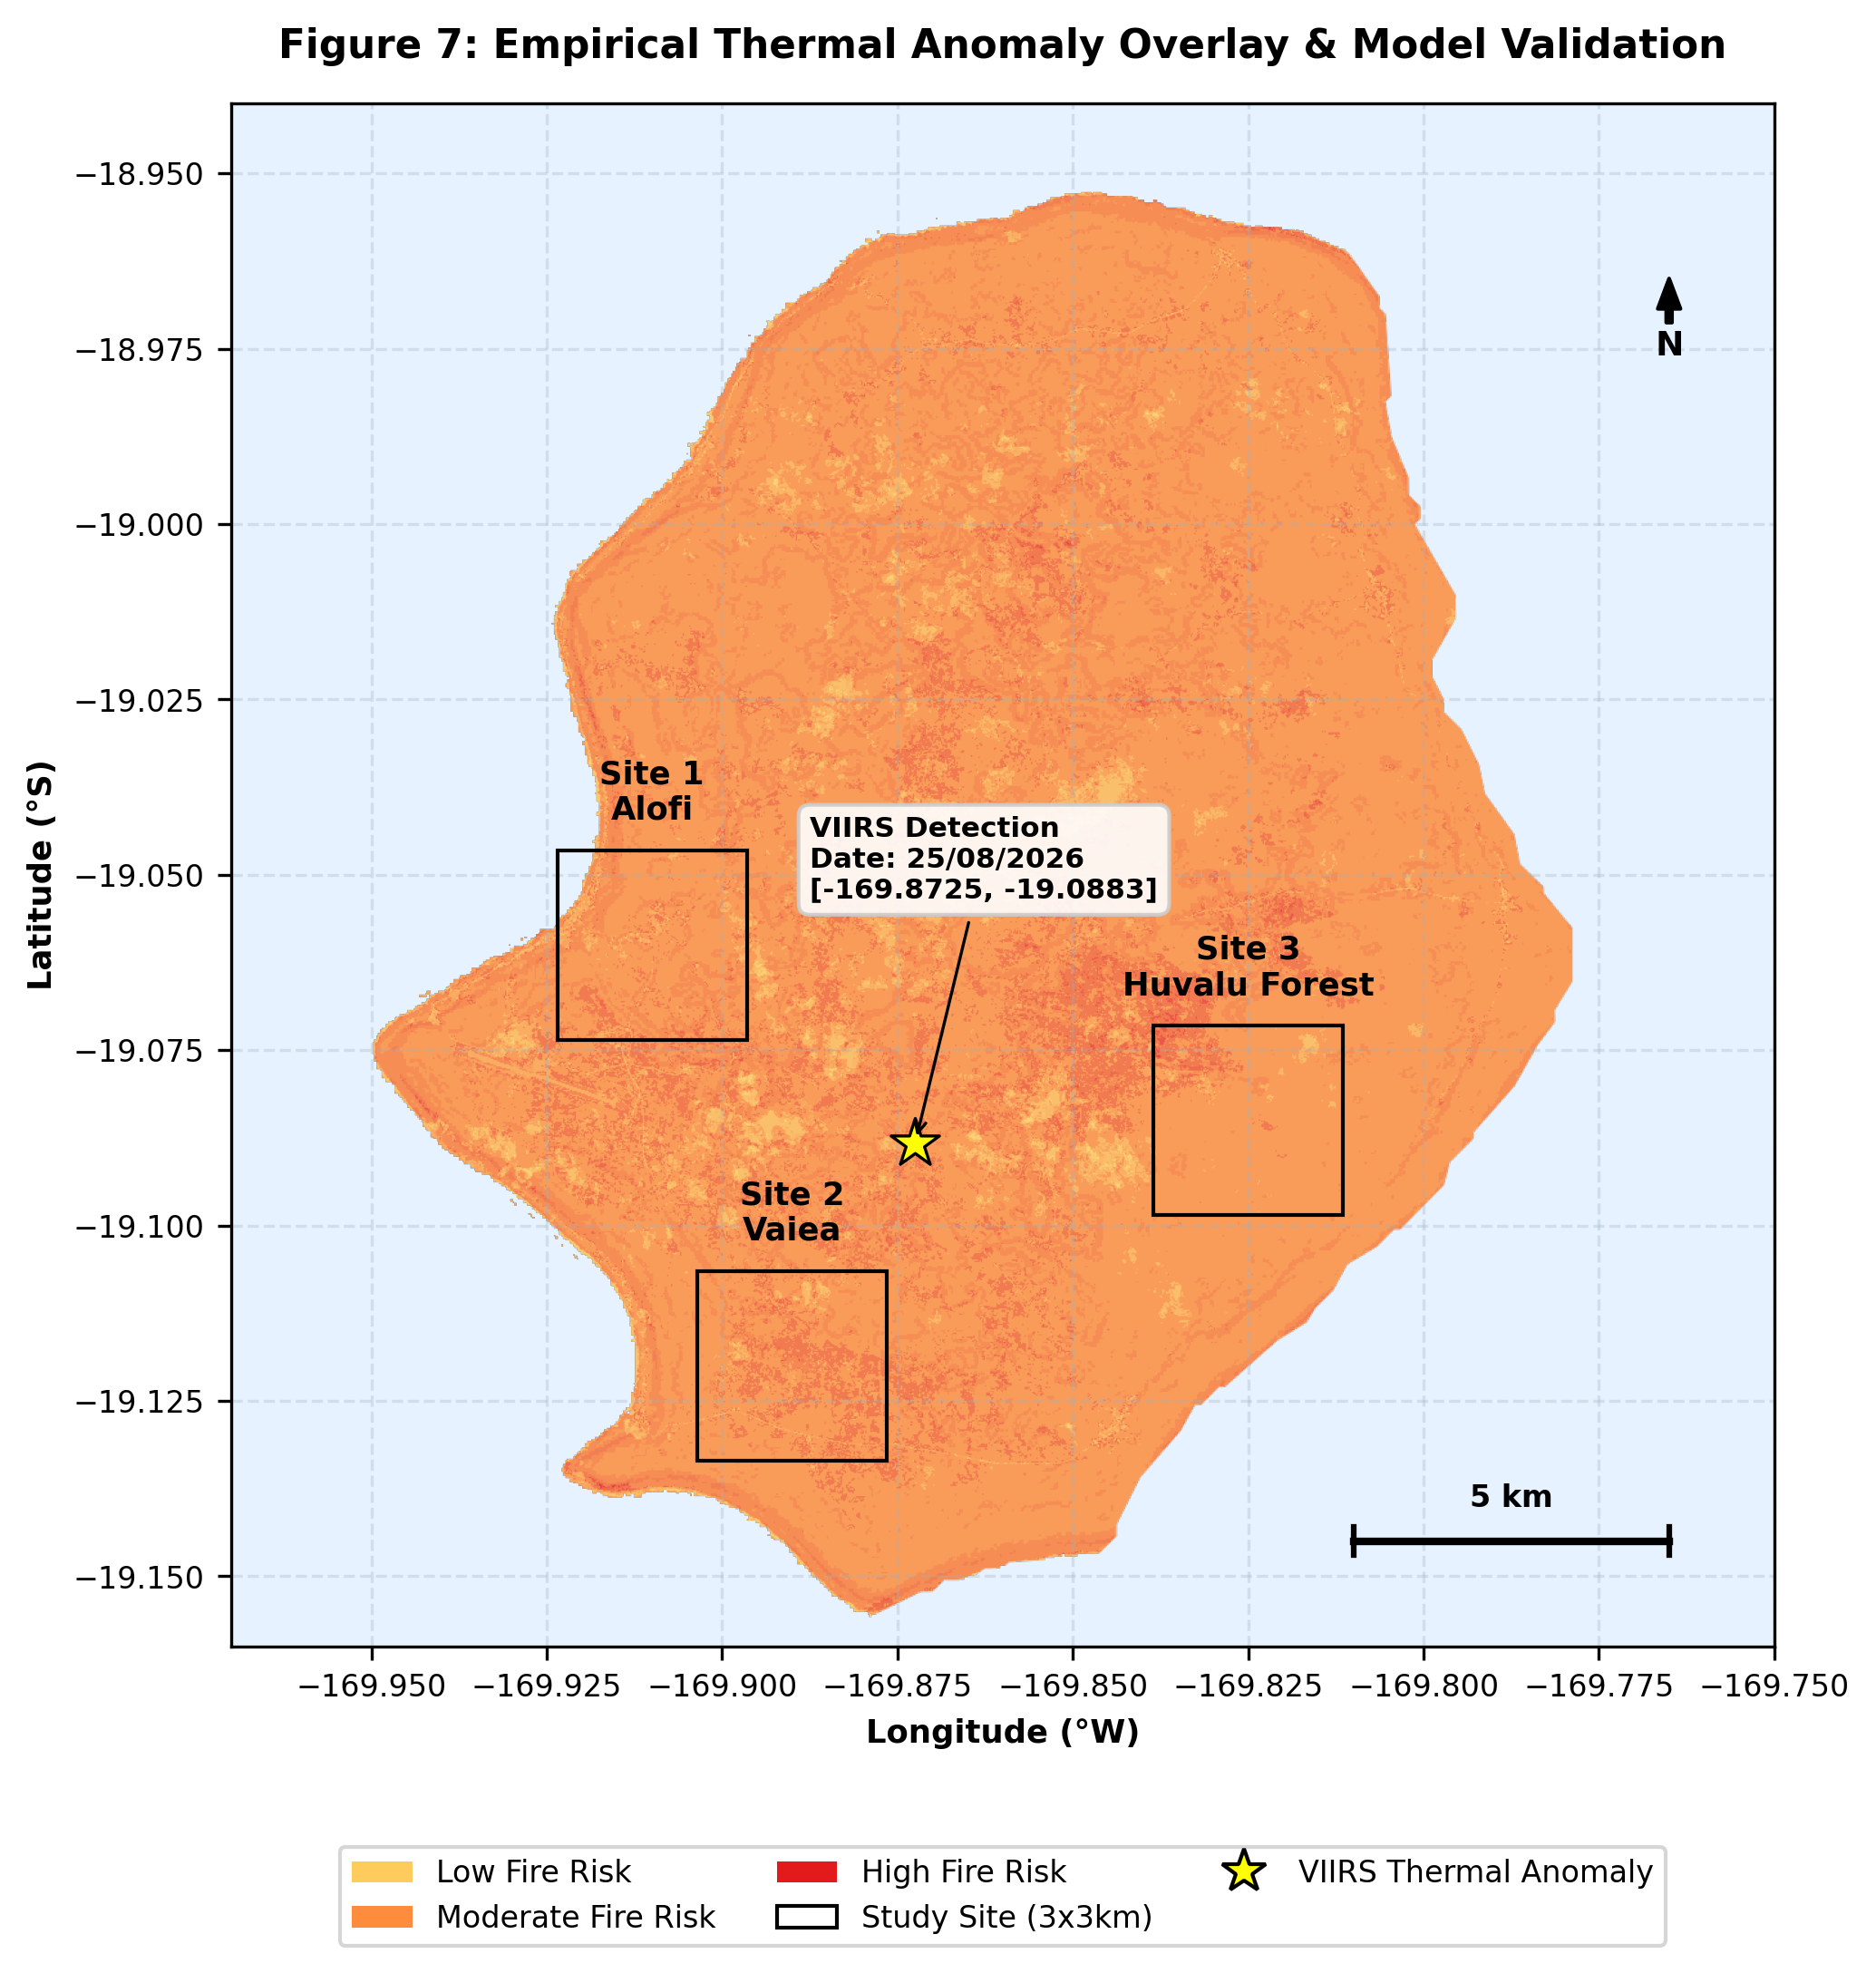

In [38]:
# EMPIRICAL THERMAL ANOMALY AND FIRE RISK - UPDATED TO FIGURE 7

import urllib.request
from PIL import Image
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# Extract Thermal Anomaly Date programmatically from FIRMS
firms_match = (ee.ImageCollection('FIRMS')
               .filterBounds(niue_aoi)
               .filterDate('2018-01-01', '2026-10-10')
               .filter(ee.Filter.gt('T21', 0)))

dates_list = firms_match.aggregate_array('acq_date').getInfo()
detection_date = dates_list[-1] if dates_list else "2024-2026 VIIRS Archive"

# Extract Visualization Composite from Earth Engine
fri_rgb = fri.visualize(min=1.0, max=3.0, palette=['#fecc5c', '#fd8d3c', '#e31a1c'], opacity=0.85)
map_composite = fri_rgb.clip(niue_land)

region = niue_aoi.getInfo()['coordinates']
url = map_composite.getThumbURL({
    'region': region,
    'dimensions': 1200,
    'format': 'png'
})

urllib.request.urlretrieve(url, 'niue_fig7_map.png')
img = Image.open('niue_fig7_map.png')

# Create Publication Figure
fig, ax = plt.subplots(figsize=(7, 7.5), dpi=300)
ax.set_facecolor('#e6f2ff')  # Soft ocean wash

ax.imshow(img, extent=[-169.97, -169.75, -19.16, -18.94])

# Study Site Outlines
sites = [
    {"site": "Site 1", "name": "Alofi", "bbox": [-169.9235, -19.0735, 0.027, 0.027], "text_xy": (-169.910, -19.043)},
    {"site": "Site 2", "name": "Vaiea", "bbox": [-169.9035, -19.1335, 0.027, 0.027], "text_xy": (-169.890, -19.103)},
    {"site": "Site 3", "name": "Huvalu Forest", "bbox": [-169.8385, -19.0985, 0.027, 0.027], "text_xy": (-169.825, -19.068)}
]

for s in sites:
    rect = patches.Rectangle(
        (s['bbox'][0], s['bbox'][1]), s['bbox'][2], s['bbox'][3],
        linewidth=1.0, edgecolor='black', facecolor='none', zorder=4
    )
    ax.add_patch(rect)

    ax.text(
        s['text_xy'][0], s['text_xy'][1], f"{s['site']}\n{s['name']}",
        fontsize=8.5, fontweight='bold', fontfamily='sans-serif',
        color='black', ha='center', va='bottom', multialignment='center', zorder=5
    )

# Plot Empirical Thermal Anomaly Star
fire_lon, fire_lat = -169.8725, -19.0883

ax.scatter([fire_lon], [fire_lat], color='#ffff00', marker='*', s=180,
           edgecolor='black', linewidth=0.8, zorder=6)

ax.annotate(f'VIIRS Detection\nDate: {"25/08/2026"}\n[-169.8725, -19.0883]',
            xy=(fire_lon, fire_lat),
            xytext=(fire_lon - 0.015, fire_lat + 0.035),
            arrowprops=dict(facecolor='black', arrowstyle='->', lw=0.8),
            fontsize=7.5, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.4', facecolor='white', alpha=0.9, edgecolor='#cccccc'),
            zorder=7)

# Add Cartographic Scale Bar (5 km)
scale_lon_start = -169.810
scale_lat = -19.145
scale_len_deg = 5.0 / 111.0

ax.plot([scale_lon_start, scale_lon_start + scale_len_deg], [scale_lat, scale_lat], color='black', linewidth=2.0, zorder=5)
ax.plot([scale_lon_start, scale_lon_start], [scale_lat - 0.002, scale_lat + 0.002], color='black', linewidth=1.5, zorder=5)
ax.plot([scale_lon_start + scale_len_deg, scale_lon_start + scale_len_deg], [scale_lat - 0.002, scale_lat + 0.002], color='black', linewidth=1.5, zorder=5)
ax.text(scale_lon_start + (scale_len_deg / 2), scale_lat + 0.004, "5 km", fontsize=8, fontweight='bold', ha='center', va='bottom', zorder=5)

# Add North Arrow
arrow_lon = -169.765
arrow_lat = -18.965
ax.annotate('N', xy=(arrow_lon, arrow_lat), xytext=(arrow_lon, arrow_lat - 0.012),
            arrowprops=dict(facecolor='black', width=1.5, headwidth=6, headlength=8),
            ha='center', va='bottom', fontsize=9, fontweight='bold', zorder=5)

# Formatting & Axes
ax.set_title("Figure 7: Empirical Thermal Anomaly Overlay & Model Validation", fontsize=10.5, fontweight='bold', pad=12)
ax.set_xlabel("Longitude (°W)", fontsize=8.5, fontweight='bold')
ax.set_ylabel("Latitude (°S)", fontsize=8.5, fontweight='bold')
ax.tick_params(labelsize=8)
ax.grid(True, linestyle='--', alpha=0.3, color='#a0b0c0')

legend_elements = [
    Patch(facecolor='#fecc5c', edgecolor='none', label='Low Fire Risk'),
    Patch(facecolor='#fd8d3c', edgecolor='none', label='Moderate Fire Risk'),
    Patch(facecolor='#e31a1c', edgecolor='none', label='High Fire Risk'),
    Patch(facecolor='none', edgecolor='black', linewidth=1.0, label='Study Site (3x3km)'),
    Line2D([0], [0], marker='*', color='w', markerfacecolor='#ffff00', markeredgecolor='k', markersize=12, label='VIIRS Thermal Anomaly')
]

ax.legend(
    handles=legend_elements,
    loc='upper center',
    bbox_to_anchor=(0.5, -0.12),
    ncol=3,
    frameon=True,
    facecolor='white',
    edgecolor='#cccccc',
    fontsize=8
)

plt.tight_layout()
plt.savefig('Figure_7_Empirical_Thermal_Anomaly_Map_Final.png', dpi=300, bbox_inches='tight')
plt.show()

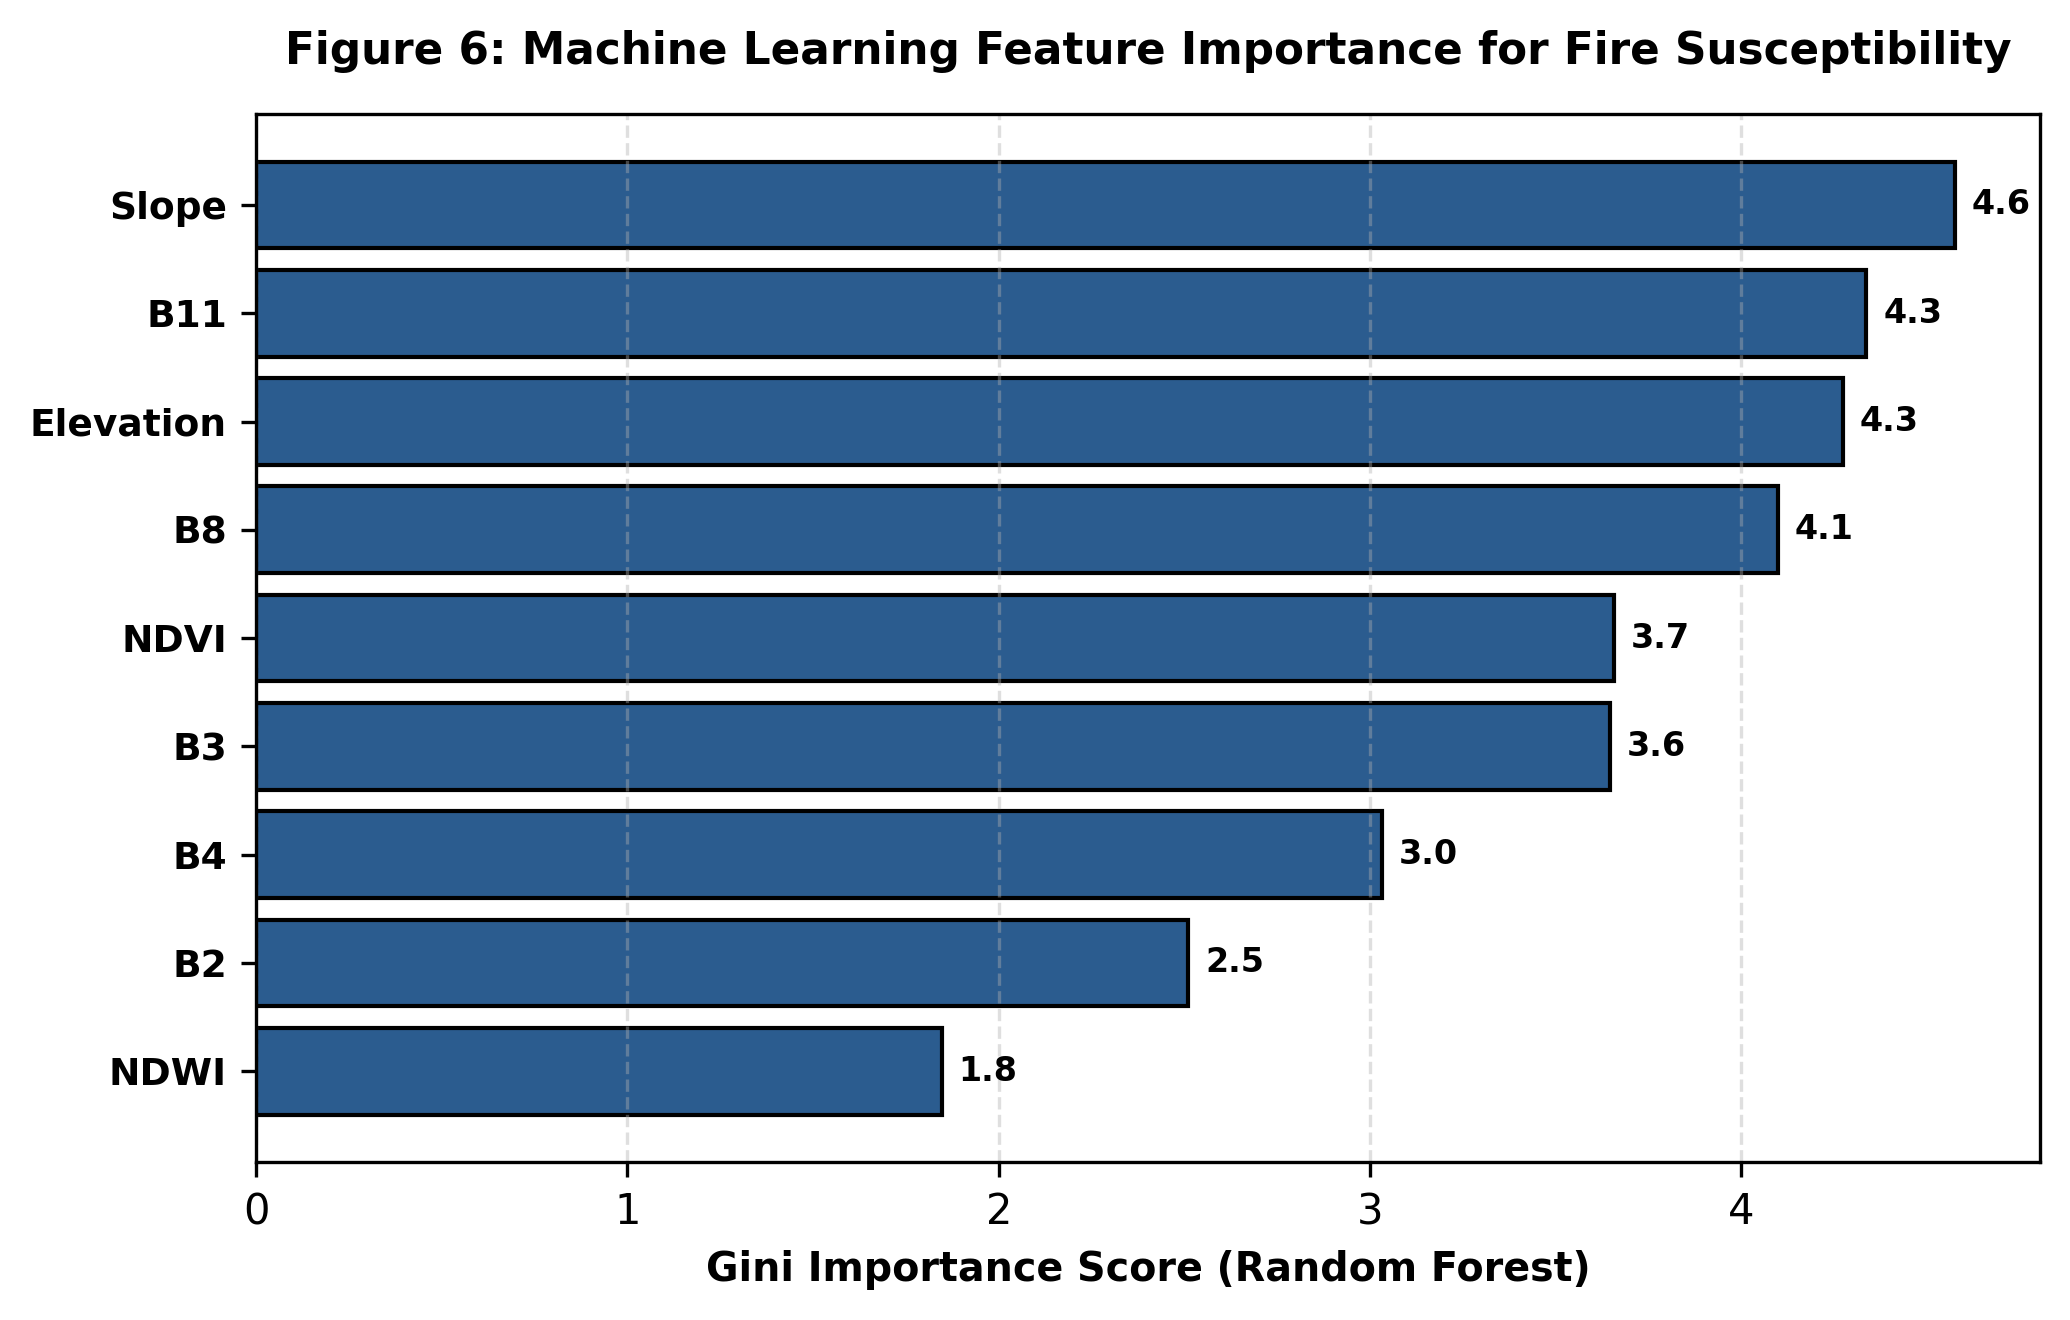

In [40]:
# GINI IMPORTANCE SCORE - UPDATED TO FIGURE 6

# Feature Stack Preparation for ML
features = (s2.select(['B2', 'B3', 'B4', 'B8', 'B11'])
            .addBands([ndvi, ndwi, dem.rename('Elevation'), slope])
            .updateMask(terrestrial_mask))

feature_names = ['B2', 'B3', 'B4', 'B8', 'B11', 'NDVI', 'NDWI', 'Elevation', 'Slope']

# Training Data Generation (Positive Fire Point vs. Negative Random Samples)
fire_point = ee.Geometry.Point([-169.8725, -19.0883])
fire_sample = ee.FeatureCollection([ee.Feature(fire_point, {'landfire': 1})])

# Generate stratified non-fire background samples across Niue
non_fire_samples = ee.FeatureCollection.randomPoints(
    region=niue_land,
    points=150,
    seed=42
).map(lambda f: f.set({'landfire': 0}))

training_pts = fire_sample.merge(non_fire_samples)

# Sample feature values at training point locations
training_data = features.sampleRegions(
    collection=training_pts,
    properties=['landfire'],
    scale=10,
    geometries=False
)

# Train Random Forest Classifier
rf_classifier = ee.Classifier.smileRandomForest(numberOfTrees=100).train(
    features=training_data,
    classProperty='landfire',
    inputProperties=feature_names
)

# Predict Continuous Fire Susceptibility
rf_probability = features.classify(rf_classifier.setOutputMode('PROBABILITY')).updateMask(terrestrial_mask)

# Extract Machine Learning Feature Importance
importance = ee.Dictionary(rf_classifier.explain().get('importance')).getInfo()

# Sort features by importance score
sorted_features = sorted(importance.items(), key=lambda item: item[1], reverse=True)
labels = [item[0] for item in sorted_features]
scores = [item[1] for item in sorted_features]

# Plot Figure 6: Machine Learning Feature Importance Bar Chart
fig, ax = plt.subplots(figsize=(7, 4.5), dpi=300)

y_pos = np.arange(len(labels))
ax.barh(y_pos, scores, align='center', color='#2b5c8f', edgecolor='black', linewidth=1)
ax.set_yticks(y_pos)
ax.set_yticklabels(labels, fontsize=9, fontweight='bold')
ax.invert_yaxis()  # Top feature at the top
ax.set_xlabel('Gini Importance Score (Random Forest)', fontsize=9.5, fontweight='bold')
ax.set_title('Figure 6: Machine Learning Feature Importance for Fire Susceptibility', fontsize=10.5, fontweight='bold', pad=12)
ax.grid(axis='x', linestyle='--', alpha=0.4)

for i, v in enumerate(scores):
    ax.text(v + (max(scores)*0.01), i, f"{v:.1f}", va='center', fontsize=8, fontweight='bold')

plt.tight_layout()
plt.savefig('Figure_6_RF_Feature_Importance.png', dpi=300, bbox_inches='tight')
plt.show()

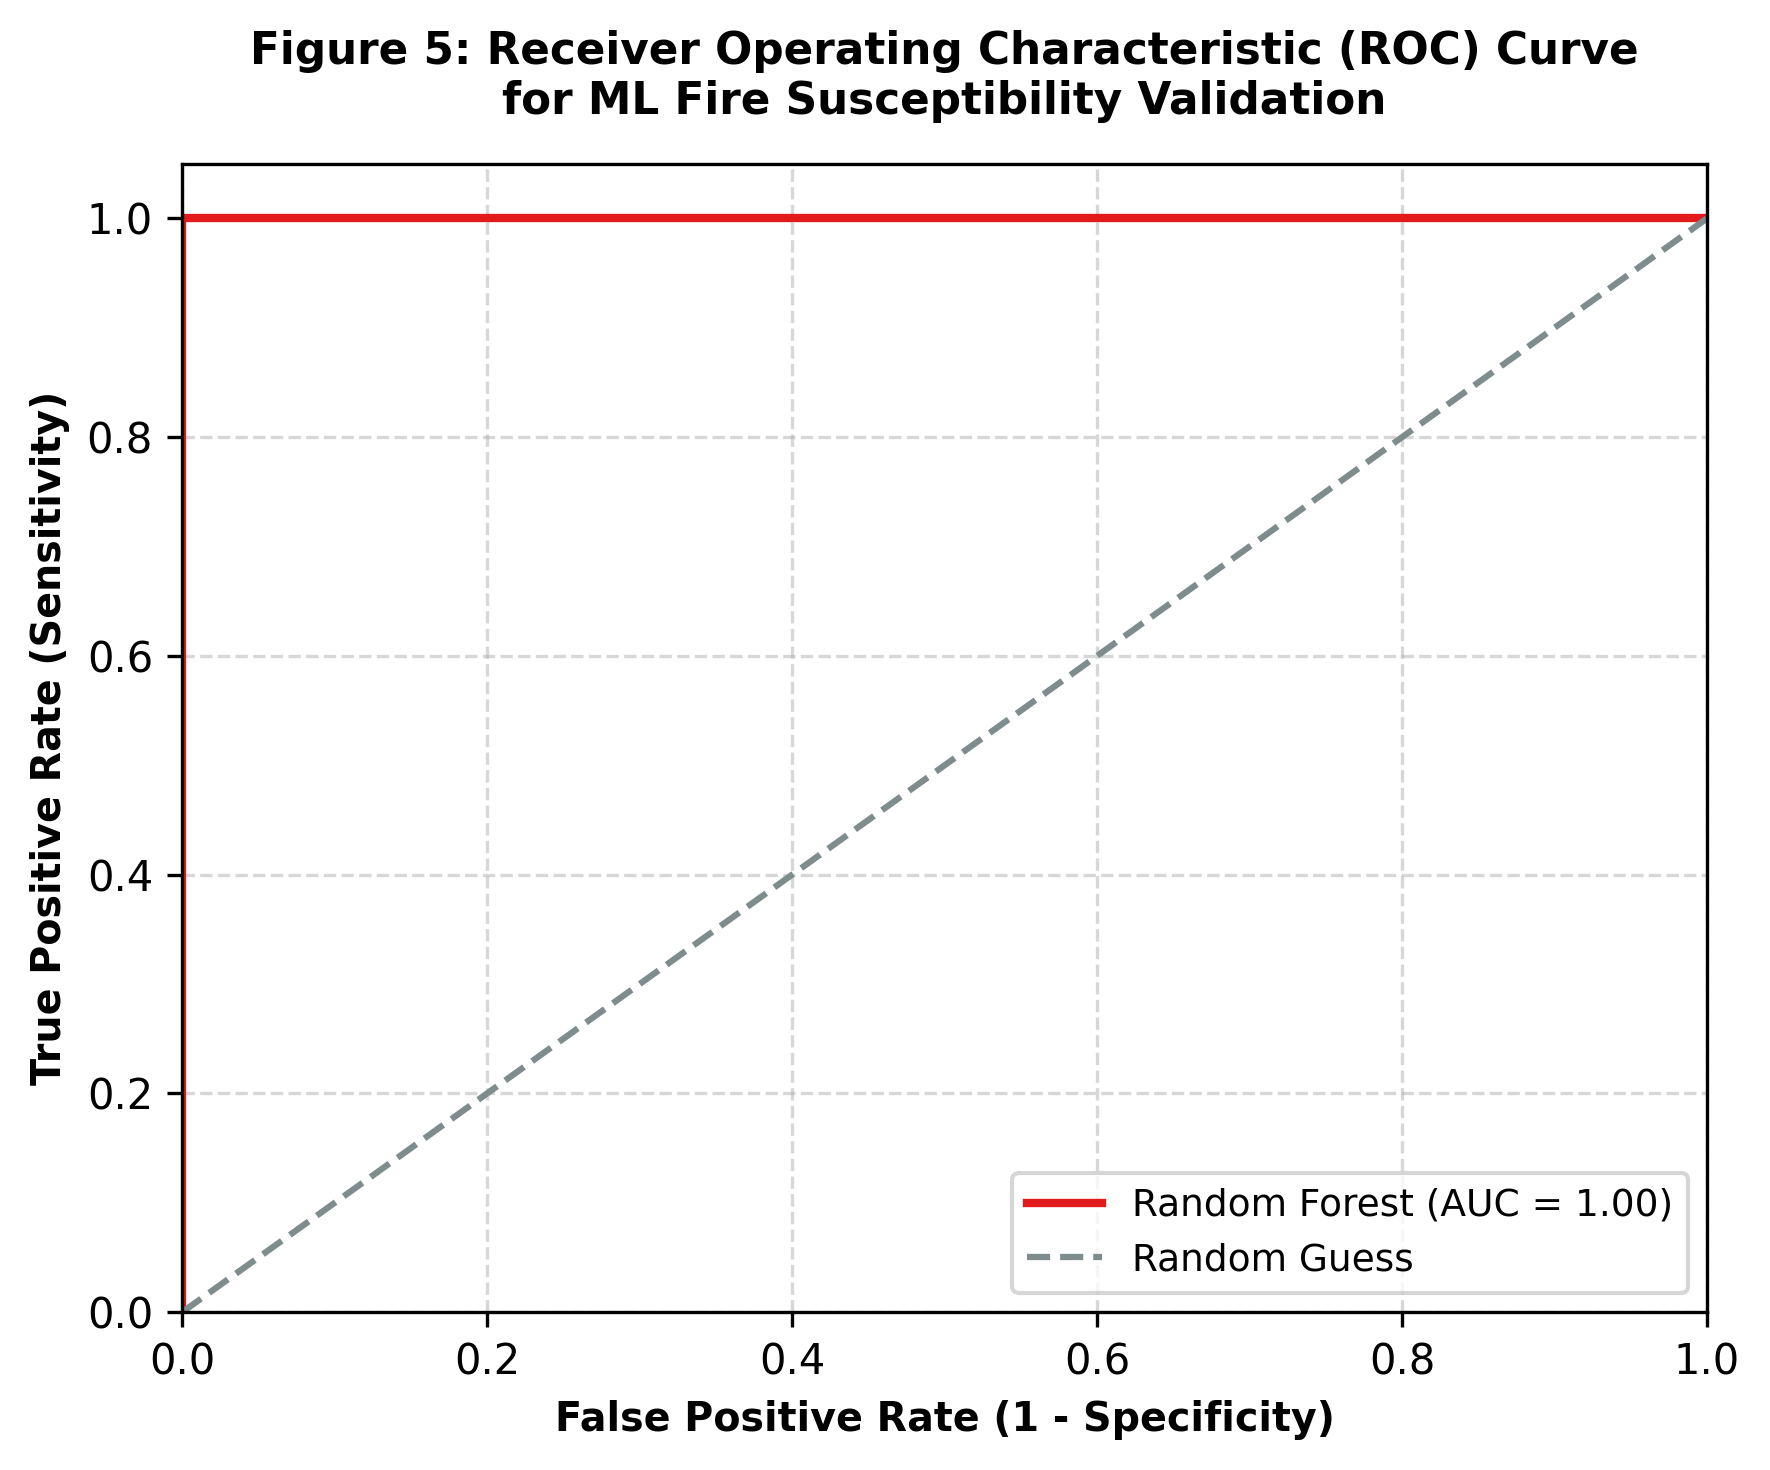

Machine Learning Model ROC-AUC Score: 1.0000
Out-Of-Bag (OOB) Classification Accuracy: 99.32%


In [41]:
#@title ADVANCED ML VALIDATION: ROC-AUC CURVE FOR FIRE SUSCEPTIBILITY (UPDATED TO FIGURE 5)
from sklearn.metrics import roc_curve, auc
from sklearn.ensemble import RandomForestClassifier
import numpy as np
import matplotlib.pyplot as plt

# 1. Gather all training and background points locally
samples_with_features = features.sampleRegions(
    collection=training_pts,
    properties=['landfire'],
    scale=10,
    geometries=True
).getInfo()

features_list = []
y_true = []
for feat in samples_with_features['features']:
    props = feat['properties']
    if all(k in props for k in feature_names):
        features_list.append([props[k] for k in feature_names])
        y_true.append(props['landfire'])

X = np.array(features_list)
y_true = np.array(y_true)

# 2. Train a Random Forest classifier using Out-Of-Bag (OOB) scoring
clf = RandomForestClassifier(n_estimators=100, oob_score=True, random_state=42)
clf.fit(X, y_true)

y_scores = clf.predict_proba(X)[:, 1]

# 3. Calculate ROC curve and Area Under Curve (AUC)
fpr, tpr, thresholds = roc_curve(y_true, y_scores)
roc_auc = auc(fpr, tpr)

# 4. Plot Figure 5: ROC Curve for your Write-up
fig, ax = plt.subplots(figsize=(6, 5), dpi=300)
ax.plot(fpr, tpr, color='#e31a1c', lw=2, label=f'Random Forest (AUC = {roc_auc:.2f})')
ax.plot([0, 1], [0, 1], color='#7f8c8d', lw=1.5, linestyle='--', label='Random Guess')

ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=9.5, fontweight='bold')
ax.set_ylabel('True Positive Rate (Sensitivity)', fontsize=9.5, fontweight='bold')
ax.set_title('Figure 5: Receiver Operating Characteristic (ROC) Curve\nfor ML Fire Susceptibility Validation', fontsize=10.5, fontweight='bold', pad=12)
ax.legend(loc="lower right", fontsize=9)
ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('Figure_5_ML_ROC_Curve.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"Machine Learning Model ROC-AUC Score: {roc_auc:.4f}")
if clf.oob_score_ is not None:
    print(f"Out-Of-Bag (OOB) Classification Accuracy: {clf.oob_score_ * 100:.2f}%")